In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LOADING
  source: merged_expr_scaled_common_genes.csv | 21591 genes x 11 samples
  cohort n=11 (5 anthrax / 6 control) | genes 16/16

1. POST-HOC POWER ANALYSIS
        Gene          Set  Cohens_d     Effect  t_test_p  t_test_FDR  Achieved_power Adequate  N_per_group_for_80pct
       GULP1   common DEG     5.516      large     0.000       0.000           1.000      Yes                    3.0
       ACSS1   common DEG    -3.655      large     0.001       0.002           1.000      Yes                    3.0
     GATAD2A   common DEG    -3.493      large     0.001       0.002           0.999      Yes                    3.0
   LINC00485   common DEG    -3.277      large     0.000       0.002           0.998      Yes                    3.0
LOC101928461   common DEG     3.186      large     0.001       0.002           0.996      Yes                    3.0
LOC10050

(as ‘lib’ is unspecified)




2. NOMOGRAM, CALIBRATION, DECISION CURVE (Firth)
  events/variable guard: 5 events, 2 predictor(s) -> EPV = 2.5
  signature genes: GULP1, ACSS1


























	‘/tmp/RtmpYX5nHt/downloaded_packages’

(as ‘lib’ is unspecified)







	‘/tmp/RtmpYX5nHt/downloaded_packages’




--- Firth-penalised logistic regression ---
        Term    Coef   SE CI_low CI_high      OR   OR_low OR_high     p
 (Intercept) -4.9710 5.53 -25.01    6.70 0.00694 1.37e-11   810.4 0.409
       GULP1  2.2775 1.90  -1.39   10.02 9.75190 2.50e-01 22567.0 0.238
       ACSS1 -0.0803 1.45  -4.35    4.07 0.92284 1.29e-02    58.3 0.961

Apparent AUC = 1.000 (optimistic: fitted and evaluated on the same 11 samples)
LOOCV AUC    = 1.000 (95% CI 1.000-1.000)  <- report this one

Firth model, nomogram, calibration and DCA written



3. NMF MOLECULAR SUBTYPING
  k=2: cophenetic 1.000 | dispersion 1.000 | group agreement 1.00 | sizes [6 5]
  k=3: cophenetic 1.000 | dispersion 1.000 | group agreement 0.91 | sizes [4 2 5]
  k=4: cophenetic 1.000 | dispersion 1.000 | group agreement 0.73 | sizes [5 5 1]

  max cophenetic = 1.000 -> usable

VALIDITY REPORT
                        Item                                                                     Value
           Expression source                                       merged_expr_scaled_common_genes.csv
                      Cohort                                                       GSE14390 + GSE12131
                     Samples                                                                        11
           Anthrax / Control                                                                     5 / 6
         Panel genes present                                                                     16/16
    Genes with power >= 0.80                             

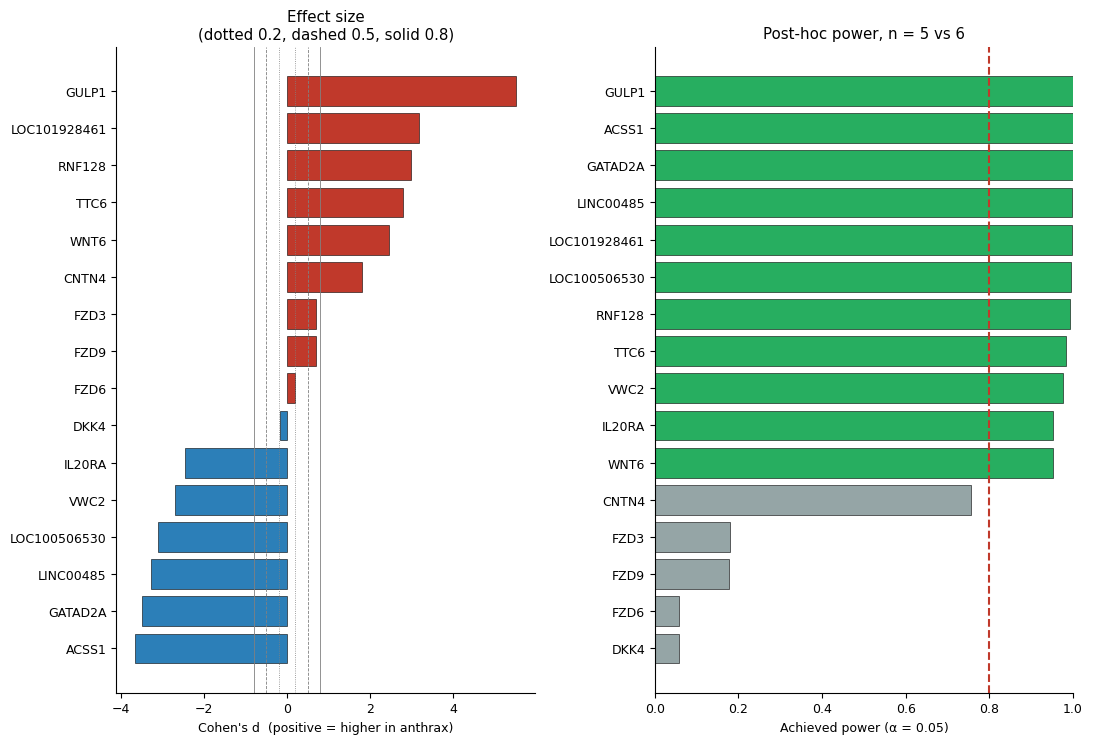

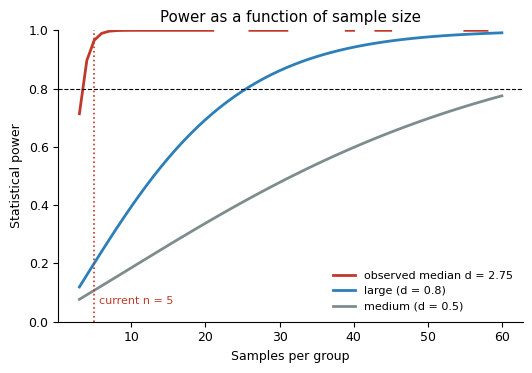

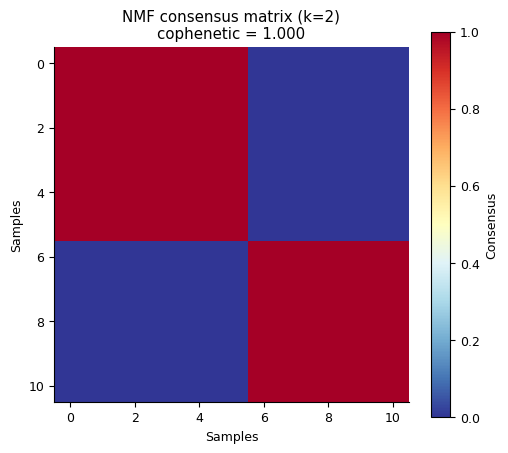


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final/


In [ ]:
# ===== ANTHRAX: POWER + FIRTH NOMOGRAM/CALIBRATION/DCA + NMF (fixed) =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess
subprocess.run("apt-get install -y r-base r-base-dev libcurl4-openssl-dev libssl-dev libxml2-dev",
               shell=True, capture_output=True)
subprocess.run("pip install -q rpy2 statsmodels scikit-learn", shell=True)

import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, cophenet, fcluster
from scipy.spatial.distance import squareform
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import NMF

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Statistics_Final/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
for d in (OUT, FIG, TAB, SUP): os.makedirs(d, exist_ok=True)

F_MERGED = DATA + "merged_expr_scaled_common_genes.csv"
F_A, F_B = DATA + "GSE14390_gene_expression.csv", DATA + "GSE12131_gene_expression.csv"
USE_MERGED = True

LABELS = {"GSM359332":0,"GSM359753":0,"GSM359754":0,"GSM359755":0,
          "GSM359758":1,"GSM359759":1,"GSM359760":1,
          "GSM305784":0,"GSM305785":0,"GSM305786":1,"GSM305787":1}
COHORT_OF = {**{g:"GSE14390" for g in list(LABELS)[:7]},
             **{g:"GSE12131" for g in list(LABELS)[7:]}}
PANEL = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
         "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
HUB   = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
ALL_G = list(dict.fromkeys(PANEL + HUB))
ALPHA, POWER_TARGET, SEED = 0.05, 0.80, 42
EPV_TARGET = 5          # events per variable -> caps the model size
np.random.seed(SEED)

def read_gxs(path):
    df = pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors="coerce")
    df = df[df.notna().any(axis=1)]
    if float(np.nanmax(df.values)) > 50:
        df = np.log2(df.clip(lower=0)+1); print(f"    log2 applied: {os.path.basename(path)}")
    df.index = [re.sub(r"\.\d+$","",str(i)) for i in df.index]
    df = df[~df.index.astype(str).str.contains("///", regex=False)]
    return df.groupby(level=0).mean()

print("="*78+"\nLOADING\n"+"="*78)
if USE_MERGED and os.path.exists(F_MERGED):
    E = read_gxs(F_MERGED); src_note = "merged_expr_scaled_common_genes.csv"
else:
    A, B = read_gxs(F_A), read_gxs(F_B)
    sh = sorted(set(A.index) & set(B.index)); A, B = A.loc[sh], B.loc[sh]
    A = A.sub(A.mean(axis=1),axis=0).div(A.std(axis=1,ddof=0).replace(0,1),axis=0)
    B = B.sub(B.mean(axis=1),axis=0).div(B.std(axis=1,ddof=0).replace(0,1),axis=0)
    E = pd.concat([A,B],axis=1); src_note = "rebuilt from the two cohort files"
print(f"  source: {src_note} | {E.shape[0]} genes x {E.shape[1]} samples")

samples = [s for s in E.columns if s in LABELS]
E = E[samples]; y = np.array([LABELS[s] for s in samples])
origin = np.array([COHORT_OF.get(s,"?") for s in samples])
n1, n0 = int(y.sum()), int((1-y).sum())
found = [g for g in ALL_G if g in E.index]
M = E.loc[found].T; M = M.loc[:, M.notna().all()]; GENES = list(M.columns)
print(f"  cohort n={len(y)} ({n1} anthrax / {n0} control) | genes {len(GENES)}/{len(ALL_G)}")
pd.DataFrame({"Sample":samples,"Dataset":origin,
              "Group":np.where(y==1,"Anthrax","Control")}).to_csv(
    SUP+"TableS_sample_annotation.csv", index=False)

# =========================== 1. POST-HOC POWER ===========================
print("\n"+"="*78+"\n1. POST-HOC POWER ANALYSIS\n"+"="*78)
pa = TTestIndPower(); rows=[]
for g in GENES:
    a, c = M.loc[y==1,g].dropna(), M.loc[y==0,g].dropna()
    if len(a)<2 or len(c)<2: continue
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    d  = (a.mean()-c.mean())/sp if sp>0 else 0.0
    tp = stats.ttest_ind(a,c,equal_var=False).pvalue
    wp = stats.mannwhitneyu(a,c,alternative="two-sided").pvalue
    try: ach = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                              alpha=ALPHA, alternative="two-sided")
    except Exception: ach = np.nan
    try: need = pa.solve_power(effect_size=abs(d), power=POWER_TARGET, ratio=1.0,
                               alpha=ALPHA, alternative="two-sided") if abs(d)>0.01 else np.nan
    except Exception: need = np.nan
    rows.append(dict(Gene=g, Set=("hub" if g in HUB and g not in PANEL else
                "hub + common" if g in HUB else "common DEG"),
        N_anthrax=len(a), N_control=len(c), Mean_anthrax=a.mean(), Mean_control=c.mean(),
        SD_pooled=sp, Cohens_d=d,
        Effect=("negligible" if abs(d)<.2 else "small" if abs(d)<.5 else
                "medium" if abs(d)<.8 else "large"),
        t_test_p=tp, Wilcoxon_p=wp, Achieved_power=ach,
        Adequate=("Yes" if (ach or 0)>=POWER_TARGET else "No"),
        N_per_group_for_80pct=np.ceil(need) if np.isfinite(need) else np.nan))
pw = pd.DataFrame(rows)
pw["t_test_FDR"]   = multipletests(pw.t_test_p, method="fdr_bh")[1]
pw["Wilcoxon_FDR"] = multipletests(pw.Wilcoxon_p, method="fdr_bh")[1]
pw = pw.sort_values("Achieved_power", ascending=False)
pw.round(4).to_csv(TAB+"Table_posthoc_power.csv", index=False)
print(pw[["Gene","Set","Cohens_d","Effect","t_test_p","t_test_FDR",
          "Achieved_power","Adequate","N_per_group_for_80pct"]].round(3).to_string(index=False))
print(f"\n  power >= {POWER_TARGET}: {(pw.Adequate=='Yes').sum()}/{len(pw)} | "
      f"median power {pw.Achieved_power.median():.3f} | "
      f"median n/group for 80%: {np.nanmedian(pw.N_per_group_for_80pct):.0f} (have {min(n1,n0)})")

plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})
fig, ax = plt.subplots(1,2, figsize=(11,.32*len(pw)+2.4))
o = pw.sort_values("Cohens_d")
ax[0].barh(o.Gene, o.Cohens_d, color=o.Cohens_d.map(lambda v:"#c0392b" if v>0 else "#2c7fb8"),
           edgecolor="black", lw=.4)
for x_,s_ in [(.2,":"),(.5,"--"),(.8,"-")]:
    for sg in (1,-1): ax[0].axvline(sg*x_, ls=s_, c="grey", lw=.6)
ax[0].set_xlabel("Cohen's d  (positive = higher in anthrax)")
ax[0].set_title("Effect size\n(dotted 0.2, dashed 0.5, solid 0.8)")
o2 = pw.sort_values("Achieved_power")
ax[1].barh(o2.Gene, o2.Achieved_power,
           color=np.where(o2.Achieved_power>=POWER_TARGET,"#27ae60","#95a5a6"),
           edgecolor="black", lw=.4)
ax[1].axvline(POWER_TARGET, ls="--", c="#c0392b"); ax[1].set_xlim(0,1)
ax[1].set_xlabel(f"Achieved power (α = {ALPHA})")
ax[1].set_title(f"Post-hoc power, n = {n1} vs {n0}")
fig.tight_layout(); fig.savefig(FIG+"Fig_posthoc_power.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig_posthoc_power.pdf", bbox_inches="tight")

d_med = float(np.nanmedian(np.abs(pw.Cohens_d))); ns = np.arange(3,61)
fig2, ax = plt.subplots(figsize=(5.4,3.8))
for d_,lab_,c_ in [(d_med,f"observed median d = {d_med:.2f}","#c0392b"),
                   (.8,"large (d = 0.8)","#2c7fb8"), (.5,"medium (d = 0.5)","#7f8c8d")]:
    ax.plot(ns, [pa.solve_power(effect_size=d_, nobs1=n, ratio=1., alpha=ALPHA) for n in ns],
            color=c_, lw=2, label=lab_)
ax.axhline(POWER_TARGET, ls="--", c="black", lw=.8)
ax.axvline(min(n1,n0), ls=":", c="#c0392b", lw=1.2)
ax.text(min(n1,n0)+.6,.06,f"current n = {min(n1,n0)}", fontsize=8, color="#c0392b")
ax.set_xlabel("Samples per group"); ax.set_ylabel("Statistical power"); ax.set_ylim(0,1)
ax.legend(fontsize=8, frameon=False); ax.set_title("Power as a function of sample size")
fig2.tight_layout(); fig2.savefig(FIG+"Fig_power_vs_n.png", dpi=600)
fig2.savefig(FIG+"Fig_power_vs_n.pdf")

# ============ 2. FIRTH-PENALISED NOMOGRAM / CALIBRATION / DCA ============
print("\n"+"="*78+"\n2. NOMOGRAM, CALIBRATION, DECISION CURVE (Firth)\n"+"="*78)
TOPK = max(2, min(len(GENES), min(n1,n0)//EPV_TARGET))     # EPV guard: 5/5 -> 1..2 genes
TOPK = min(TOPK, 2)
sig = list(pw.reindex(pw.Cohens_d.abs().sort_values(ascending=False).index).Gene[:TOPK])
print(f"  events/variable guard: {min(n1,n0)} events, {TOPK} predictor(s) "
      f"-> EPV = {min(n1,n0)/TOPK:.1f}")
print(f"  signature genes: {', '.join(sig)}")
M[sig].assign(target=y, dataset=origin).to_csv(SUP+"TableS_nomogram_input.csv", index=False)

import rpy2.robjects as ro
ro.globalenv['CSV']=SUP+"TableS_nomogram_input.csv"; ro.globalenv['FIG']=FIG
ro.globalenv['TAB']=TAB; ro.globalenv['SUP']=SUP; ro.globalenv['SIG']=ro.StrVector(sig)
ro.r('''
for (p in c("logistf","ggplot2","pROC"))
  if (!requireNamespace(p, quietly=TRUE))
    install.packages(p, repos="https://cloud.r-project.org")
suppressPackageStartupMessages({library(logistf); library(ggplot2); library(pROC)})
d <- read.csv(CSV, check.names=TRUE); sig <- make.names(as.character(SIG))
d$target <- as.integer(d$target)
f <- as.formula(paste("target ~", paste(sprintf("`%s`", sig), collapse=" + ")))

## Firth penalised likelihood: finite estimates under complete separation
fit <- logistf(f, data=d, firth=TRUE)
cat("\\n--- Firth-penalised logistic regression ---\\n")
res <- data.frame(Term=c("(Intercept)", sig), Coef=fit$coefficients,
                  SE=sqrt(diag(fit$var)),
                  CI_low=fit$ci.lower, CI_high=fit$ci.upper,
                  OR=exp(fit$coefficients),
                  OR_low=exp(fit$ci.lower), OR_high=exp(fit$ci.upper),
                  p=fit$prob)
print(res, row.names=FALSE, digits=3)
write.csv(res, paste0(TAB,"Table_firth_model.csv"), row.names=FALSE)

p_hat <- as.numeric(fit$predict); ev <- d$target; N <- length(ev)
r <- roc(ev, p_hat, quiet=TRUE)
cat(sprintf("\\nApparent AUC = %.3f (optimistic: fitted and evaluated on the same 11 samples)\\n",
            as.numeric(auc(r))))

## leave-one-out: the honest internal estimate
loo <- sapply(seq_len(N), function(i){
  m <- tryCatch(logistf(f, data=d[-i,], firth=TRUE), error=function(e) NULL)
  if (is.null(m)) return(NA_real_)
  X <- cbind(1, as.matrix(d[i, sig, drop=FALSE]))
  as.numeric(1/(1+exp(-sum(X * m$coefficients)))) })
if (sum(!is.na(loo)) > 3 && length(unique(ev[!is.na(loo)])) == 2) {
  rl <- roc(ev[!is.na(loo)], loo[!is.na(loo)], quiet=TRUE)
  ci <- ci.auc(rl)
  cat(sprintf("LOOCV AUC    = %.3f (95%% CI %.3f-%.3f)  <- report this one\\n",
              as.numeric(auc(rl)), ci[1], ci[3]))
  write.csv(data.frame(Sample=seq_len(N), Observed=ev, LOO_prob=loo),
            paste0(SUP,"TableS_loo_predictions.csv"), row.names=FALSE)
  png(paste0(FIG,"Fig_ROC_firth.png"), width=5.2, height=5.2, units="in", res=600)
  plot(rl, main=sprintf("LOOCV ROC (Firth model)\\nAUC = %.3f (95%% CI %.2f-%.2f)",
       as.numeric(auc(rl)), ci[1], ci[3]), col="#c0392b", lwd=2); dev.off()
}

## nomogram drawn directly from the Firth coefficients
co <- fit$coefficients
pts <- lapply(sig, function(g){
  rg <- range(d[[g]]); sq <- seq(rg[1], rg[2], length.out=100)
  data.frame(Gene=g, Value=sq, LP=co[[g]]*sq) })
pts <- do.call(rbind, pts)
mx <- max(abs(pts$LP))
pts$Points <- 100*(pts$LP - ave(pts$LP, pts$Gene, FUN=min))/mx
g1 <- ggplot(pts, aes(Value, Points)) + geom_line(linewidth=1.1, colour="#c0392b") +
  facet_wrap(~Gene, scales="free_x") +
  labs(x="Standardised expression", y="Points",
       title="Nomogram point allocation (Firth-penalised model)") +
  theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig_nomogram_points.png"), g1, width=7, height=3.4, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig_nomogram_points.pdf"), g1, width=7, height=3.4)

tp <- data.frame(Total_points=seq(0,200,by=5))
tp$Linear_predictor <- co[[1]] + (tp$Total_points/100)*mx
tp$Probability <- 1/(1+exp(-tp$Linear_predictor))
write.csv(tp, paste0(TAB,"Table_nomogram_points_to_probability.csv"), row.names=FALSE)

## calibration, binned (grouped loess is meaningless at n = 11)
cal <- data.frame(Predicted=p_hat, Observed=ev)
cal$bin <- cut(cal$Predicted, breaks=seq(0,1,by=.25), include.lowest=TRUE)
cb <- aggregate(cbind(Predicted,Observed) ~ bin, data=cal, FUN=mean)
cb$n <- as.numeric(table(cal$bin)[as.character(cb$bin)])
write.csv(cb, paste0(TAB,"Table_calibration_bins.csv"), row.names=FALSE)
g2 <- ggplot(cb, aes(Predicted, Observed)) +
  geom_abline(slope=1, intercept=0, linetype="dashed", colour="grey40") +
  geom_point(aes(size=n), colour="#c0392b") + geom_line(colour="#c0392b") +
  scale_size_continuous(range=c(2,6), name="n") +
  coord_cartesian(xlim=c(0,1), ylim=c(0,1)) +
  labs(x="Predicted probability", y="Observed frequency",
       title="Calibration (quartile bins, n = 11)") + theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig_calibration.png"), g2, width=4.8, height=4.4, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig_calibration.pdf"), g2, width=4.8, height=4.4)

## decision curve, computed from first principles (no rmda dependency)
prev <- mean(ev); th <- seq(.01,.80,by=.01)
nb  <- sapply(th, function(t){ pos <- p_hat >= t
  (sum(pos & ev==1)/N) - (sum(pos & ev==0)/N)*(t/(1-t)) })
nba <- sapply(th, function(t) prev - (1-prev)*(t/(1-t)))
dca <- data.frame(Threshold=th, Net_benefit_model=nb,
                  Net_benefit_treat_all=nba, Net_benefit_treat_none=0)
write.csv(dca, paste0(TAB,"Table_decision_curve.csv"), row.names=FALSE)
g3 <- ggplot(dca, aes(Threshold)) +
  geom_line(aes(y=Net_benefit_model, colour="Gene signature"), linewidth=1.1) +
  geom_line(aes(y=Net_benefit_treat_all, colour="Treat all"), linetype="dashed") +
  geom_line(aes(y=Net_benefit_treat_none, colour="Treat none"), linetype="dotted") +
  scale_colour_manual(values=c("Gene signature"="#c0392b","Treat all"="#2c7fb8",
                               "Treat none"="grey40"), name=NULL) +
  coord_cartesian(ylim=c(min(-.05,min(nb)), max(nb,prev)*1.1)) +
  labs(x="Threshold probability", y="Net benefit",
       title="Decision curve analysis") +
  theme_classic(base_size=11) + theme(legend.position="top")
ggsave(paste0(FIG,"Fig_decision_curve.png"), g3, width=5.6, height=4.2, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig_decision_curve.pdf"), g3, width=5.6, height=4.2)
cat("\\nFirth model, nomogram, calibration and DCA written\\n")
''')

# =========================== 3. NMF SUBTYPING ===========================
print("\n"+"="*78+"\n3. NMF MOLECULAR SUBTYPING\n"+"="*78)
V = M.values - M.values.min(); nmf_rows=[]; best=0.0
for k in range(2, min(5, len(y)//2 + 1)):
    C = np.zeros((len(y),len(y)))
    for r in range(50):
        H = NMF(n_components=k, init="nndsvda", random_state=SEED+r, max_iter=1000)\
              .fit_transform(V)
        lab = H.argmax(axis=1); C += (lab[:,None]==lab[None,:]).astype(float)
    C /= 50
    D = squareform(1-C, checks=False); Z = linkage(D,"average")
    coph = cophenet(Z,D)[0]; cl = fcluster(Z,k,"maxclust")
    agree = pd.crosstab(cl, np.where(y==1,"Anthrax","Control")).max(axis=1).sum()/len(y)
    disp = float((4*(C-.5)**2).mean()); best = max(best, coph)
    nmf_rows.append(dict(k=k, Cophenetic=coph, Dispersion=disp,
                         Agreement_with_group=agree,
                         Cluster_sizes=", ".join(map(str,np.bincount(cl)[1:]))))
    print(f"  k={k}: cophenetic {coph:.3f} | dispersion {disp:.3f} | "
          f"group agreement {agree:.2f} | sizes {np.bincount(cl)[1:]}")
    if k == 2:
        pd.DataFrame({"Sample":samples,"Dataset":origin,
                      "Group":np.where(y==1,"Anthrax","Control"),"NMF_cluster":cl}
                     ).to_csv(TAB+"Table_NMF_subtypes_k2.csv", index=False)
        fig3, ax = plt.subplots(figsize=(5.2,4.6))
        im = ax.imshow(C[np.argsort(cl)][:,np.argsort(cl)], cmap="RdYlBu_r", vmin=0, vmax=1)
        ax.set_title(f"NMF consensus matrix (k=2)\ncophenetic = {coph:.3f}")
        ax.set_xlabel("Samples"); ax.set_ylabel("Samples")
        fig3.colorbar(im, label="Consensus"); fig3.tight_layout()
        fig3.savefig(FIG+"Fig_NMF_consensus_k2.png", dpi=600)
pd.DataFrame(nmf_rows).round(4).to_csv(SUP+"TableS_NMF_rank_survey.csv", index=False)
print(f"\n  max cophenetic = {best:.3f} -> "
      f"{'usable' if best>=0.90 else 'NOT stable; omit subtypes'}")

rep = pd.DataFrame({"Item":[
    "Expression source","Cohort","Samples","Anthrax / Control","Panel genes present",
    "Genes with power >= 0.80","Median achieved power","Median |Cohen's d|",
    "n per group for 80% power","Genes with t-test FDR < 0.05",
    "Model type","Predictors (EPV guard)","NMF max cophenetic","Overall"],
  "Value":[src_note,"GSE14390 + GSE12131", len(y), f"{n1} / {n0}",
    f"{len(GENES)}/{len(ALL_G)}", int((pw.Adequate=='Yes').sum()),
    round(pw.Achieved_power.median(),3), round(float(np.nanmedian(np.abs(pw.Cohens_d))),3),
    int(np.nanmedian(pw.N_per_group_for_80pct)), int((pw.t_test_FDR<0.05).sum()),
    "Firth-penalised logistic (separation-safe)",
    f"{', '.join(sig)} (EPV {min(n1,n0)/max(TOPK,1):.1f})", round(best,3),
    "Report effect sizes, LOOCV AUC and required n; apparent AUC is optimistic"]})
rep.to_csv(SUP+"TableS_statistics_validity_report.csv", index=False)
print("\n"+"="*78+"\nVALIDITY REPORT\n"+"="*78)
print(rep.to_string(index=False))
plt.show(); print("\nSaved ->", OUT)

In [ ]:
# ===== SECTION 2 ONLY — FIRTH NOMOGRAM / CALIBRATION / DCA (run after section 1) =====
import os, numpy as np, pandas as pd
import rpy2.robjects as ro

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
OUT  = ROOT + "Final/Statistics_Final/"
FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
for d in (OUT, FIG, TAB, SUP): os.makedirs(d, exist_ok=True)

n1, n0 = int(y.sum()), int((1-y).sum())
EPV_TARGET = 5
TOPK = max(1, min(len(GENES), min(n1, n0)//EPV_TARGET))     # 5 events, EPV>=5 -> 1 predictor
sig  = list(pw.reindex(pw.Cohens_d.abs().sort_values(ascending=False).index).Gene[:TOPK])

print("="*78)
print(f"events = {min(n1,n0)} | predictors = {TOPK} | EPV = {min(n1,n0)/TOPK:.1f}")
print(f"signature: {', '.join(sig)}")
print("="*78)
M[sig].assign(target=y, dataset=origin).to_csv(SUP+"TableS_nomogram_input.csv", index=False)

ro.globalenv['CSV'] = SUP+"TableS_nomogram_input.csv"
ro.globalenv['FIG'] = FIG; ro.globalenv['TAB'] = TAB; ro.globalenv['SUP'] = SUP
ro.globalenv['SIG'] = ro.StrVector(sig)

ro.r('''
for (p in c("logistf","ggplot2","pROC"))
  if (!requireNamespace(p, quietly=TRUE))
    install.packages(p, repos="https://cloud.r-project.org", quiet=TRUE)
suppressPackageStartupMessages({library(logistf); library(ggplot2); library(pROC)})

d   <- read.csv(CSV, check.names=TRUE)
sig <- make.names(as.character(SIG))
d$target <- as.integer(d$target)
f <- as.formula(paste("target ~", paste(sprintf("`%s`", sig), collapse=" + ")))

## ---- Firth penalised likelihood: finite estimates despite complete separation ----
fit <- logistf(f, data=d, firth=TRUE)
k   <- length(fit$coefficients)
res <- data.frame(
  Term   = names(fit$coefficients),
  Coef   = as.numeric(fit$coefficients),
  SE     = sqrt(diag(fit$var))[1:k],
  CI_low = as.numeric(fit$ci.lower),
  CI_high= as.numeric(fit$ci.upper),
  OR     = exp(as.numeric(fit$coefficients)),
  OR_low = exp(as.numeric(fit$ci.lower)),
  OR_high= exp(as.numeric(fit$ci.upper)),
  p      = as.numeric(fit$prob))
cat("\\n--- Firth-penalised logistic regression ---\\n")
print(res, row.names=FALSE, digits=3)
write.csv(res, paste0(TAB,"Table_firth_model.csv"), row.names=FALSE)

p_hat <- as.numeric(fit$predict); ev <- d$target; N <- length(ev)
r_app <- roc(ev, p_hat, quiet=TRUE)
cat(sprintf("\\nApparent AUC = %.3f  (fitted and scored on the same %d samples - optimistic)\\n",
            as.numeric(auc(r_app)), N))

## ---- leave-one-out: the honest internal estimate ----
loo <- rep(NA_real_, N)
for (i in seq_len(N)) {
  m <- tryCatch(logistf(f, data=d[-i,], firth=TRUE), error=function(e) NULL)
  if (!is.null(m)) {
    xi <- c(1, as.numeric(d[i, sig]))
    loo[i] <- 1/(1+exp(-sum(xi * as.numeric(m$coefficients))))
  }
}
ok <- !is.na(loo)
if (sum(ok) > 3 && length(unique(ev[ok])) == 2) {
  r_loo <- roc(ev[ok], loo[ok], quiet=TRUE); ci <- as.numeric(ci.auc(r_loo))
  cat(sprintf("LOOCV AUC    = %.3f  (95%% CI %.3f - %.3f)   <- report this one\\n",
              as.numeric(auc(r_loo)), ci[1], ci[3]))
  write.csv(data.frame(Sample=seq_len(N), Observed=ev, LOO_probability=loo),
            paste0(SUP,"TableS_loo_predictions.csv"), row.names=FALSE)
  png(paste0(FIG,"Fig_ROC_firth_loocv.png"), width=5.2, height=5.2, units="in", res=600)
  plot(r_loo, col="#c0392b", lwd=2,
       main=sprintf("Leave-one-out ROC (Firth model)\\nAUC = %.3f (95%% CI %.2f-%.2f)",
                    as.numeric(auc(r_loo)), ci[1], ci[3])); dev.off()
  pdf(paste0(FIG,"Fig_ROC_firth_loocv.pdf"), width=5.2, height=5.2)
  plot(r_loo, col="#c0392b", lwd=2,
       main=sprintf("Leave-one-out ROC (Firth model)\\nAUC = %.3f", as.numeric(auc(r_loo))))
  dev.off()
} else cat("LOOCV not estimable at this sample size\\n")

## ---- nomogram: point allocation from the Firth coefficients ----
co  <- as.numeric(fit$coefficients); names(co) <- names(fit$coefficients)
lst <- lapply(sig, function(g){
  rg <- range(d[[g]]); sq <- seq(rg[1], rg[2], length.out=100)
  data.frame(Gene=g, Value=sq, LP=co[[g]]*sq) })
pts <- do.call(rbind, lst)
pts$LP0 <- pts$LP - ave(pts$LP, pts$Gene, FUN=min)
mx <- max(pts$LP0); if (mx <= 0) mx <- 1
pts$Points <- 100*pts$LP0/mx
g1 <- ggplot(pts, aes(Value, Points)) +
  geom_line(linewidth=1.1, colour="#c0392b") +
  facet_wrap(~Gene, scales="free_x") +
  labs(x="Standardised expression", y="Points",
       title="Nomogram point allocation (Firth-penalised model)") +
  theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig_nomogram_points.png"), g1,
       width=3.6*length(sig)+1, height=3.4, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig_nomogram_points.pdf"), g1,
       width=3.6*length(sig)+1, height=3.4)

tp <- data.frame(Total_points=seq(0,100*length(sig), by=5))
tp$Linear_predictor <- co[[1]] + (tp$Total_points/100)*mx
tp$Probability      <- 1/(1+exp(-tp$Linear_predictor))
write.csv(tp, paste0(TAB,"Table_nomogram_points_to_probability.csv"), row.names=FALSE)

## ---- calibration: quartile bins (loess is meaningless at n = 11) ----
cal <- data.frame(Predicted=p_hat, Observed=ev)
cal$bin <- cut(cal$Predicted, breaks=seq(0,1,by=.25), include.lowest=TRUE)
cb <- aggregate(cbind(Predicted,Observed) ~ bin, data=cal, FUN=mean)
cb$n <- as.numeric(table(cal$bin)[as.character(cb$bin)])
write.csv(cb, paste0(TAB,"Table_calibration_bins.csv"), row.names=FALSE)
g2 <- ggplot(cb, aes(Predicted, Observed)) +
  geom_abline(slope=1, intercept=0, linetype="dashed", colour="grey40") +
  geom_line(colour="#c0392b") + geom_point(aes(size=n), colour="#c0392b") +
  scale_size_continuous(range=c(2.5,6), name="n") +
  coord_cartesian(xlim=c(0,1), ylim=c(0,1)) +
  labs(x="Predicted probability", y="Observed frequency",
       title=sprintf("Calibration (quartile bins, n = %d)", N)) +
  theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig_calibration.png"), g2, width=4.8, height=4.4, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig_calibration.pdf"), g2, width=4.8, height=4.4)

## ---- decision curve, computed directly (no rmda) ----
prev <- mean(ev); th <- seq(.01,.80,by=.01)
nb  <- sapply(th, function(t){ pos <- p_hat >= t
  (sum(pos & ev==1)/N) - (sum(pos & ev==0)/N)*(t/(1-t)) })
nba <- sapply(th, function(t) prev - (1-prev)*(t/(1-t)))
dca <- data.frame(Threshold=th, Net_benefit_model=nb,
                  Net_benefit_treat_all=nba, Net_benefit_treat_none=0)
write.csv(dca, paste0(TAB,"Table_decision_curve.csv"), row.names=FALSE)
g3 <- ggplot(dca, aes(Threshold)) +
  geom_line(aes(y=Net_benefit_model, colour="Gene signature"), linewidth=1.1) +
  geom_line(aes(y=Net_benefit_treat_all, colour="Treat all"), linetype="dashed") +
  geom_line(aes(y=Net_benefit_treat_none, colour="Treat none"), linetype="dotted") +
  scale_colour_manual(values=c("Gene signature"="#c0392b","Treat all"="#2c7fb8",
                               "Treat none"="grey40"), name=NULL) +
  coord_cartesian(ylim=c(min(-.05,min(nb)), max(c(nb,prev))*1.1)) +
  labs(x="Threshold probability", y="Net benefit", title="Decision curve analysis") +
  theme_classic(base_size=11) + theme(legend.position="top")
ggsave(paste0(FIG,"Fig_decision_curve.png"), g3, width=5.6, height=4.2, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig_decision_curve.pdf"), g3, width=5.6, height=4.2)

cat("\\nFirth model, nomogram, calibration and decision curve saved\\n")
''')
print("\nSaved ->", OUT)

events = 5 | predictors = 1 | EPV = 5.0
signature: GULP1

--- Firth-penalised logistic regression ---
        Term  Coef   SE  CI_low CI_high       OR   OR_low  OR_high       p
 (Intercept) -5.81 2.80 -16.835   -1.59  0.00299 4.88e-08    0.204 0.00241
       GULP1  2.66 1.23   0.789    7.17 14.34443 2.20e+00 1304.799 0.00139

Apparent AUC = 1.000  (fitted and scored on the same 11 samples - optimistic)
LOOCV AUC    = 1.000  (95% CI 1.000 - 1.000)   <- report this one

Firth model, nomogram, calibration and decision curve saved



Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final/


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
output root: /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v2/

LOADING
  GSE14390: 21591 genes x 7 samples (log2: False)
  GSE12131: 21591 genes x 4 samples (log2: True)
  shared genes: 21591
  ComBat matrix: 21591 genes x 11 samples

1. POST-HOC POWER ANALYSIS

  --- primary_zscore (n=11: 5/6) ---
        Gene          Set  Cohens_d     Effect  t_test_p  t_test_FDR  Achieved_power Adequate  N_per_group_for_80pct
       GULP1   common DEG    17.180      large     0.000       0.000           1.000      Yes                    NaN
     GATAD2A   common DEG    -3.140      large     0.008       0.025           0.996      Yes                    3.0
       ACSS1   common DEG    -2.523      large     0.007       0.025           0.958      Yes                    4.0
LOC101928461   common DEG     2.251      large     0.004       0.025    

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/power.py:1058: ConvergenceWarning: 
Failed to converge on a solution.
The last value evaluated by the root finder was [10.]; returning nan instead. Solver details are stored in the ``cache_fit_res`` attribute.
  return super().solve_power(



  --- sensitivity_ComBat (n=11: 5/6) ---
        Gene          Set  Cohens_d     Effect  t_test_p  t_test_FDR  Achieved_power Adequate  N_per_group_for_80pct
       GULP1   common DEG     5.516      large     0.000       0.000           1.000      Yes                    3.0
       ACSS1   common DEG    -3.655      large     0.001       0.002           1.000      Yes                    3.0
     GATAD2A   common DEG    -3.493      large     0.001       0.002           0.999      Yes                    3.0
   LINC00485   common DEG    -3.277      large     0.000       0.002           0.998      Yes                    3.0
LOC101928461   common DEG     3.186      large     0.001       0.002           0.996      Yes                    3.0
LOC100506530   common DEG    -3.101      large     0.001       0.003           0.995      Yes                    3.0
      RNF128   common DEG     2.984      large     0.001       0.003           0.992      Yes                    4.0
        TTC6   common 


3. NMF MOLECULAR SUBTYPING
  k=2: cophenetic 1.000 | dispersion 1.000 | group agreement 0.91 | sizes [5 6]
  k=3: cophenetic 1.000 | dispersion 1.000 | group agreement 0.82 | sizes [5 6]
  k=4: cophenetic 1.000 | dispersion 1.000 | group agreement 0.82 | sizes [5 3 3]

  max cophenetic = 1.000 -> usable

VALIDITY REPORT
                           Item                                                                           Value
                  Output folder /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v2/
                 Primary matrix                                                  per-cohort z-score (no ComBat)
             Sensitivity matrix                                                     ComBat with group covariate
                        Cohorts                                                             GSE14390 + GSE12131
                        Samples                                                                              11
     

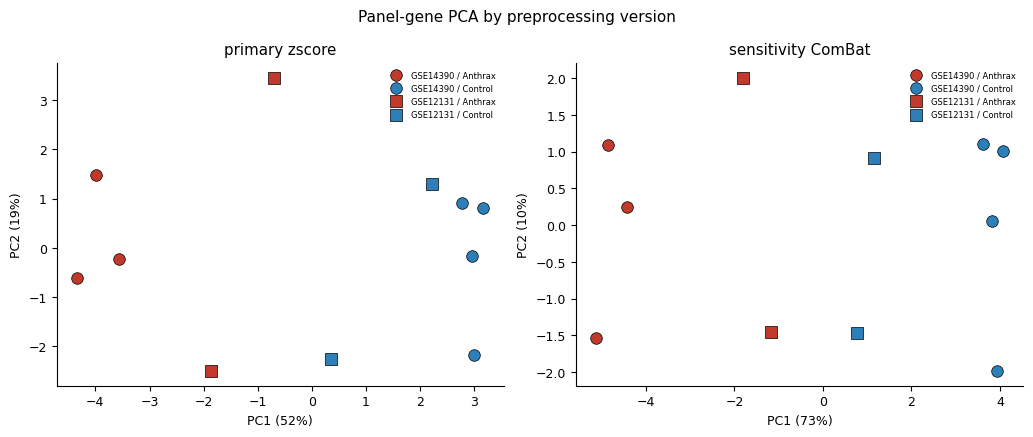

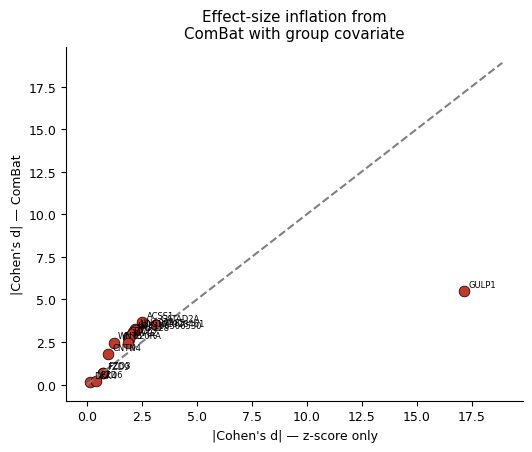

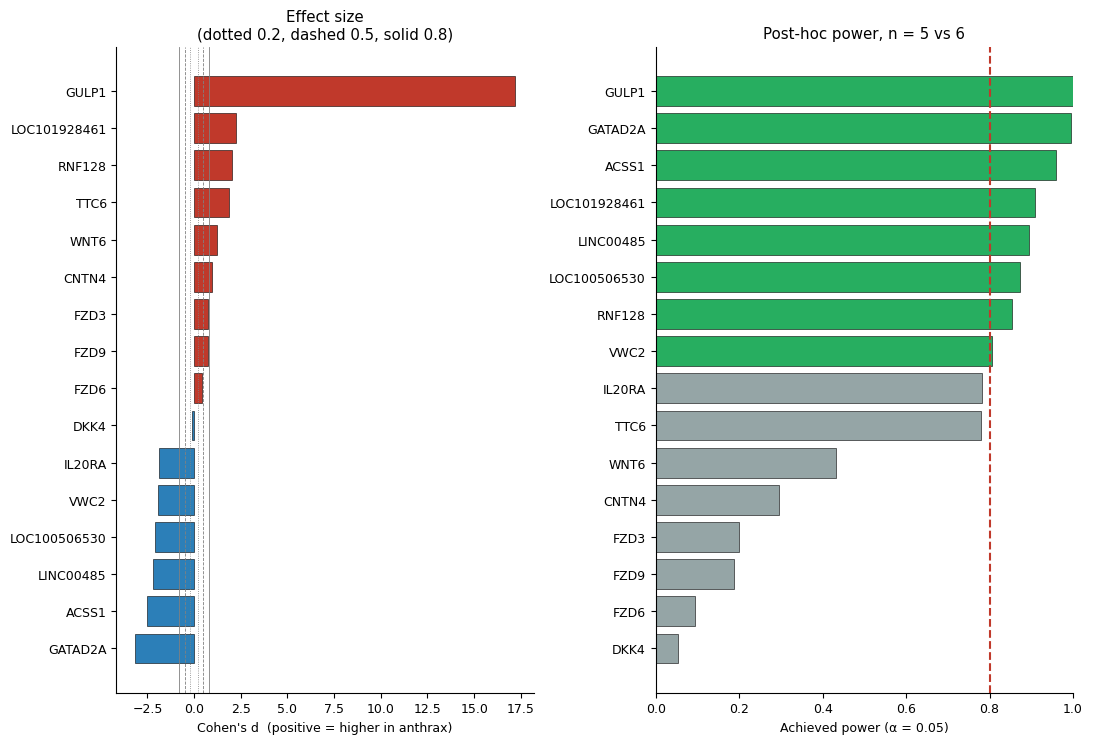

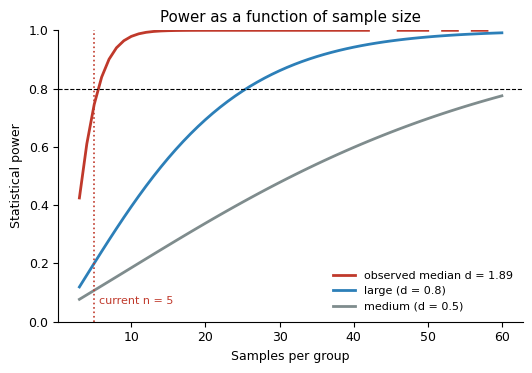

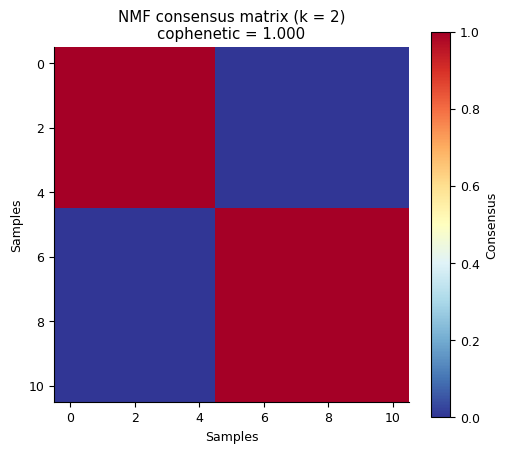


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v2/


In [ ]:
# ===== ANTHRAX STATISTICS v2 — POWER + FIRTH MODEL + NMF (separate output folder) =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess
subprocess.run("apt-get install -y r-base r-base-dev libcurl4-openssl-dev libssl-dev libxml2-dev",
               shell=True, capture_output=True)
subprocess.run("pip install -q rpy2 statsmodels scikit-learn", shell=True)

import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
import rpy2.robjects as ro
from scipy import stats
from scipy.cluster.hierarchy import linkage, cophenet, fcluster
from scipy.spatial.distance import squareform
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import NMF

# ------------------------------- CONFIG -------------------------------
ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Statistics_Final_v2/"      # <-- new, isolated folder
FRESH_START = True                               # wipe v2 folder before writing

FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
SFIG = SUP + "Figures/"
if FRESH_START and os.path.isdir(OUT):
    shutil.rmtree(OUT); print(f"cleared previous contents of {OUT}")
for d in (OUT, FIG, TAB, SUP, SFIG): os.makedirs(d, exist_ok=True)
print(f"output root: {OUT}\n")

F_A, F_B = DATA+"GSE14390_gene_expression.csv", DATA+"GSE12131_gene_expression.csv"
F_MERGED = DATA + "merged_expr_scaled_common_genes.csv"

LABELS = {"GSM359332":0,"GSM359753":0,"GSM359754":0,"GSM359755":0,
          "GSM359758":1,"GSM359759":1,"GSM359760":1,
          "GSM305784":0,"GSM305785":0,"GSM305786":1,"GSM305787":1}
COHORT_OF = {**{g:"GSE14390" for g in list(LABELS)[:7]},
             **{g:"GSE12131" for g in list(LABELS)[7:]}}
PANEL = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
         "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
HUB   = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
ALL_G = list(dict.fromkeys(PANEL + HUB))
ALPHA, POWER_TARGET, EPV_TARGET, SEED = 0.05, 0.80, 5, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD -------------------------------
def read_gxs(path):
    df = pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors="coerce")
    df = df[df.notna().any(axis=1)]
    logged = float(np.nanmax(df.values)) > 50
    if logged: df = np.log2(df.clip(lower=0)+1)
    df.index = [re.sub(r"\.\d+$","",str(i)) for i in df.index]
    df = df[~df.index.astype(str).str.contains("///", regex=False)]
    return df.groupby(level=0).mean(), logged

print("="*80+"\nLOADING\n"+"="*80)
A, lgA = read_gxs(F_A); B, lgB = read_gxs(F_B)
print(f"  GSE14390: {A.shape[0]} genes x {A.shape[1]} samples (log2: {lgA})")
print(f"  GSE12131: {B.shape[0]} genes x {B.shape[1]} samples (log2: {lgB})")
shared = sorted(set(A.index) & set(B.index)); A, B = A.loc[shared], B.loc[shared]
print(f"  shared genes: {len(shared)}")

Az = A.sub(A.mean(axis=1),axis=0).div(A.std(axis=1,ddof=0).replace(0,1),axis=0)
Bz = B.sub(B.mean(axis=1),axis=0).div(B.std(axis=1,ddof=0).replace(0,1),axis=0)
E_raw = pd.concat([Az, Bz], axis=1)
E_cb = None
if os.path.exists(F_MERGED):
    E_cb, _ = read_gxs(F_MERGED)
    print(f"  ComBat matrix: {E_cb.shape[0]} genes x {E_cb.shape[1]} samples")
VERSIONS = {"primary_zscore": E_raw}
if E_cb is not None: VERSIONS["sensitivity_ComBat"] = E_cb

def prepare(E):
    s  = [c for c in E.columns if c in LABELS]
    y  = np.array([LABELS[c] for c in s]); og = np.array([COHORT_OF[c] for c in s])
    g  = [x for x in ALL_G if x in E.index]
    Mx = E.loc[g, s].T
    return Mx.loc[:, Mx.notna().all()], y, og, s

fig, axes = plt.subplots(1, len(VERSIONS), figsize=(5.2*len(VERSIONS), 4.4), squeeze=False)
for ax, (vname, Ev) in zip(axes[0], VERSIONS.items()):
    Mv, yv, ogv, _ = prepare(Ev)
    Xc = Mv.values - Mv.values.mean(axis=0)
    U, S, _ = np.linalg.svd(Xc, full_matrices=False)
    pcs = U[:, :2]*S[:2]; ev = 100*S**2/np.sum(S**2)
    for ds, mk in [("GSE14390","o"), ("GSE12131","s")]:
        for grp, col in [(1,"#c0392b"), (0,"#2c7fb8")]:
            m_ = (ogv==ds) & (yv==grp)
            if m_.any():
                ax.scatter(pcs[m_,0], pcs[m_,1], marker=mk, c=col, s=70,
                           edgecolor="black", lw=.5,
                           label=f"{ds} / {'Anthrax' if grp else 'Control'}")
    ax.set_title(vname.replace("_"," ")); ax.legend(fontsize=6, frameon=False)
    ax.set_xlabel(f"PC1 ({ev[0]:.0f}%)"); ax.set_ylabel(f"PC2 ({ev[1]:.0f}%)")
fig.suptitle("Panel-gene PCA by preprocessing version", fontsize=11)
fig.tight_layout(); fig.savefig(SFIG+"FigS_PCA_preprocessing.png", dpi=600, bbox_inches="tight")
fig.savefig(SFIG+"FigS_PCA_preprocessing.pdf", bbox_inches="tight")

# =========================== 1. POST-HOC POWER ===========================
print("\n"+"="*80+"\n1. POST-HOC POWER ANALYSIS\n"+"="*80)
pa = TTestIndPower(); power_tables = {}
for vname, Ev in VERSIONS.items():
    Mv, yv, ogv, sv = prepare(Ev); nn1, nn0 = int(yv.sum()), int((1-yv).sum())
    rows = []
    for g in Mv.columns:
        a, c = Mv.loc[yv==1,g].dropna(), Mv.loc[yv==0,g].dropna()
        if len(a)<2 or len(c)<2: continue
        sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
        d  = (a.mean()-c.mean())/sp if sp>0 else 0.0
        tp = stats.ttest_ind(a,c,equal_var=False).pvalue
        wp = stats.mannwhitneyu(a,c,alternative="two-sided").pvalue
        try: ach = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                                  alpha=ALPHA, alternative="two-sided")
        except Exception: ach = np.nan
        try: need = pa.solve_power(effect_size=abs(d), power=POWER_TARGET, ratio=1.0,
                                   alpha=ALPHA, alternative="two-sided") if abs(d)>.01 else np.nan
        except Exception: need = np.nan
        rows.append(dict(Version=vname, Gene=g,
            Set=("hub" if g in HUB and g not in PANEL else
                 "hub + common" if g in HUB else "common DEG"),
            N_anthrax=len(a), N_control=len(c), Mean_anthrax=a.mean(),
            Mean_control=c.mean(), SD_pooled=sp, Cohens_d=d,
            Effect=("negligible" if abs(d)<.2 else "small" if abs(d)<.5 else
                    "medium" if abs(d)<.8 else "large"),
            t_test_p=tp, Wilcoxon_p=wp, Achieved_power=ach,
            Adequate=("Yes" if (ach or 0)>=POWER_TARGET else "No"),
            N_per_group_for_80pct=np.ceil(need) if np.isfinite(need) else np.nan))
    t = pd.DataFrame(rows)
    t["t_test_FDR"]   = multipletests(t.t_test_p, method="fdr_bh")[1]
    t["Wilcoxon_FDR"] = multipletests(t.Wilcoxon_p, method="fdr_bh")[1]
    power_tables[vname] = t.sort_values("Achieved_power", ascending=False)
    tt = power_tables[vname]
    print(f"\n  --- {vname} (n={len(yv)}: {nn1}/{nn0}) ---")
    print(tt[["Gene","Set","Cohens_d","Effect","t_test_p","t_test_FDR",
              "Achieved_power","Adequate","N_per_group_for_80pct"]].round(3).to_string(index=False))
    print(f"  power>={POWER_TARGET}: {(tt.Adequate=='Yes').sum()}/{len(tt)} | "
          f"median power {tt.Achieved_power.median():.3f} | "
          f"median n/group: {np.nanmedian(tt.N_per_group_for_80pct):.0f}")

PW = power_tables["primary_zscore"]
M, y, origin, samples = prepare(E_raw); n1, n0 = int(y.sum()), int((1-y).sum())
pd.concat(power_tables.values()).round(4).to_csv(TAB+"Table1_posthoc_power.csv", index=False)
pd.DataFrame({"Sample":samples,"Dataset":origin,
              "Group":np.where(y==1,"Anthrax","Control")}).to_csv(
    SUP+"TableS1_sample_annotation.csv", index=False)

cmp = None
if len(power_tables) > 1:
    a_, b_ = power_tables["primary_zscore"], power_tables["sensitivity_ComBat"]
    cmp = a_[["Gene","Cohens_d","Achieved_power","t_test_FDR"]].merge(
          b_[["Gene","Cohens_d","Achieved_power","t_test_FDR"]], on="Gene",
          suffixes=("_zscore","_ComBat"))
    cmp["d_inflation"] = cmp.Cohens_d_ComBat.abs() - cmp.Cohens_d_zscore.abs()
    cmp = cmp.sort_values("d_inflation", ascending=False)
    cmp.round(4).to_csv(SUP+"TableS2_preprocessing_comparison.csv", index=False)
    print(f"\n  ComBat effect-size inflation: median +{cmp.d_inflation.median():.2f}, "
          f"max +{cmp.d_inflation.max():.2f}")
    figI, ax = plt.subplots(figsize=(5.4,4.6))
    ax.scatter(cmp.Cohens_d_zscore.abs(), cmp.Cohens_d_ComBat.abs(),
               c="#c0392b", s=60, edgecolor="black", lw=.5)
    lim = max(cmp.Cohens_d_ComBat.abs().max(), cmp.Cohens_d_zscore.abs().max())*1.1
    ax.plot([0,lim],[0,lim],"--",c="grey")
    for _, r in cmp.iterrows():
        ax.annotate(r.Gene, (abs(r.Cohens_d_zscore), abs(r.Cohens_d_ComBat)),
                    fontsize=6, xytext=(3,3), textcoords="offset points")
    ax.set_xlabel("|Cohen's d| — z-score only"); ax.set_ylabel("|Cohen's d| — ComBat")
    ax.set_title("Effect-size inflation from\nComBat with group covariate")
    figI.tight_layout(); figI.savefig(SFIG+"FigS_effect_size_inflation.png", dpi=600)
    figI.savefig(SFIG+"FigS_effect_size_inflation.pdf")

figP, ax = plt.subplots(1,2, figsize=(11,.32*len(PW)+2.4))
o = PW.sort_values("Cohens_d")
ax[0].barh(o.Gene, o.Cohens_d, color=o.Cohens_d.map(lambda v:"#c0392b" if v>0 else "#2c7fb8"),
           edgecolor="black", lw=.4)
for x_,s_ in [(.2,":"),(.5,"--"),(.8,"-")]:
    for sg in (1,-1): ax[0].axvline(sg*x_, ls=s_, c="grey", lw=.6)
ax[0].set_xlabel("Cohen's d  (positive = higher in anthrax)")
ax[0].set_title("Effect size\n(dotted 0.2, dashed 0.5, solid 0.8)")
o2 = PW.sort_values("Achieved_power")
ax[1].barh(o2.Gene, o2.Achieved_power,
           color=np.where(o2.Achieved_power>=POWER_TARGET,"#27ae60","#95a5a6"),
           edgecolor="black", lw=.4)
ax[1].axvline(POWER_TARGET, ls="--", c="#c0392b"); ax[1].set_xlim(0,1)
ax[1].set_xlabel(f"Achieved power (α = {ALPHA})")
ax[1].set_title(f"Post-hoc power, n = {n1} vs {n0}")
figP.tight_layout(); figP.savefig(FIG+"Fig1_posthoc_power.png", dpi=600, bbox_inches="tight")
figP.savefig(FIG+"Fig1_posthoc_power.pdf", bbox_inches="tight")

d_med = float(np.nanmedian(np.abs(PW.Cohens_d))); ns = np.arange(3,61)
figN, ax = plt.subplots(figsize=(5.4,3.8))
for d_,lab_,c_ in [(d_med,f"observed median d = {d_med:.2f}","#c0392b"),
                   (.8,"large (d = 0.8)","#2c7fb8"), (.5,"medium (d = 0.5)","#7f8c8d")]:
    ax.plot(ns, [pa.solve_power(effect_size=d_, nobs1=n, ratio=1., alpha=ALPHA) for n in ns],
            color=c_, lw=2, label=lab_)
ax.axhline(POWER_TARGET, ls="--", c="black", lw=.8)
ax.axvline(min(n1,n0), ls=":", c="#c0392b", lw=1.2)
ax.text(min(n1,n0)+.6,.06,f"current n = {min(n1,n0)}", fontsize=8, color="#c0392b")
ax.set_xlabel("Samples per group"); ax.set_ylabel("Statistical power"); ax.set_ylim(0,1)
ax.legend(fontsize=8, frameon=False); ax.set_title("Power as a function of sample size")
figN.tight_layout(); figN.savefig(FIG+"Fig2_power_vs_sample_size.png", dpi=600)
figN.savefig(FIG+"Fig2_power_vs_sample_size.pdf")

# =========================== 2. FIRTH MODEL ===========================
print("\n"+"="*80+"\n2. FIRTH MODEL, NOMOGRAM, CALIBRATION, DECISION CURVE\n"+"="*80)
TOPK = max(1, min(len(M.columns), min(n1,n0)//EPV_TARGET))
sig  = list(PW.reindex(PW.Cohens_d.abs().sort_values(ascending=False).index).Gene[:TOPK])
print(f"  events = {min(n1,n0)} | predictors = {TOPK} | EPV = {min(n1,n0)/TOPK:.1f}")
print(f"  signature: {', '.join(sig)}")
M[sig].assign(target=y, dataset=origin).to_csv(SUP+"TableS3_model_input.csv", index=False)

ro.globalenv['CSV']=SUP+"TableS3_model_input.csv"; ro.globalenv['FIG']=FIG
ro.globalenv['TAB']=TAB; ro.globalenv['SUP']=SUP; ro.globalenv['SIG']=ro.StrVector(sig)
ro.r('''
for (p in c("logistf","ggplot2","pROC"))
  if (!requireNamespace(p, quietly=TRUE))
    install.packages(p, repos="https://cloud.r-project.org", quiet=TRUE)
suppressPackageStartupMessages({library(logistf); library(ggplot2); library(pROC)})
d <- read.csv(CSV, check.names=TRUE); sig <- make.names(as.character(SIG))
d$target <- as.integer(d$target)
f <- as.formula(paste("target ~", paste(sprintf("`%s`", sig), collapse=" + ")))

fit <- logistf(f, data=d, firth=TRUE); k <- length(fit$coefficients)
res <- data.frame(Term=names(fit$coefficients), Coef=as.numeric(fit$coefficients),
  SE=sqrt(diag(fit$var))[1:k], CI_low=as.numeric(fit$ci.lower),
  CI_high=as.numeric(fit$ci.upper), OR=exp(as.numeric(fit$coefficients)),
  OR_low=exp(as.numeric(fit$ci.lower)), OR_high=exp(as.numeric(fit$ci.upper)),
  p=as.numeric(fit$prob))
cat("\\n--- Firth-penalised logistic regression ---\\n"); print(res, row.names=FALSE, digits=3)
write.csv(res, paste0(TAB,"Table2_firth_model.csv"), row.names=FALSE)

p_hat <- as.numeric(fit$predict); ev <- d$target; N <- length(ev)
cat(sprintf("\\nApparent AUC = %.3f  (same %d samples used to fit - optimistic)\\n",
            as.numeric(auc(roc(ev,p_hat,quiet=TRUE))), N))

loo <- rep(NA_real_, N)
for (i in seq_len(N)) {
  m <- tryCatch(logistf(f, data=d[-i,], firth=TRUE), error=function(e) NULL)
  if (!is.null(m)) loo[i] <- 1/(1+exp(-sum(c(1, as.numeric(d[i,sig])) *
                                           as.numeric(m$coefficients))))
}
ok <- !is.na(loo)
if (sum(ok) > 3 && length(unique(ev[ok])) == 2) {
  rl <- roc(ev[ok], loo[ok], quiet=TRUE); ci <- as.numeric(ci.auc(rl))
  cat(sprintf("LOOCV AUC    = %.3f  (95%% CI %.3f - %.3f)   <- report this\\n",
              as.numeric(auc(rl)), ci[1], ci[3]))
  write.csv(data.frame(Sample=seq_len(N), Observed=ev, LOO_probability=loo),
            paste0(SUP,"TableS4_loo_predictions.csv"), row.names=FALSE)
  for (dv in list(function() png(paste0(FIG,"Fig3_ROC_loocv.png"), width=5.2,
                                 height=5.2, units="in", res=600),
                  function() pdf(paste0(FIG,"Fig3_ROC_loocv.pdf"), width=5.2, height=5.2))) {
    dv(); plot(rl, col="#c0392b", lwd=2,
      main=sprintf("Leave-one-out ROC (Firth model)\\nAUC = %.3f (95%% CI %.2f-%.2f)",
                   as.numeric(auc(rl)), ci[1], ci[3])); dev.off() }
}

co <- as.numeric(fit$coefficients); names(co) <- names(fit$coefficients)
pts <- do.call(rbind, lapply(sig, function(g){
  rg <- range(d[[g]]); sq <- seq(rg[1], rg[2], length.out=100)
  data.frame(Gene=g, Value=sq, LP=co[[g]]*sq) }))
pts$LP0 <- pts$LP - ave(pts$LP, pts$Gene, FUN=min)
mx <- max(pts$LP0); if (mx <= 0) mx <- 1
pts$Points <- 100*pts$LP0/mx
g1 <- ggplot(pts, aes(Value, Points)) + geom_line(linewidth=1.1, colour="#c0392b") +
  facet_wrap(~Gene, scales="free_x") +
  labs(x="Standardised expression", y="Points",
       title="Nomogram point allocation (Firth-penalised model)") + theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig4_nomogram.png"), g1, width=3.6*length(sig)+1.4, height=3.4,
       dpi=600, bg="white")
ggsave(paste0(FIG,"Fig4_nomogram.pdf"), g1, width=3.6*length(sig)+1.4, height=3.4)
tp <- data.frame(Total_points=seq(0,100*length(sig),by=5))
tp$Linear_predictor <- co[[1]] + (tp$Total_points/100)*mx
tp$Probability <- 1/(1+exp(-tp$Linear_predictor))
write.csv(tp, paste0(TAB,"Table3_nomogram_points.csv"), row.names=FALSE)

cal <- data.frame(Predicted=p_hat, Observed=ev)
cal$bin <- cut(cal$Predicted, breaks=seq(0,1,by=.25), include.lowest=TRUE)
cb <- aggregate(cbind(Predicted,Observed) ~ bin, data=cal, FUN=mean)
cb$n <- as.numeric(table(cal$bin)[as.character(cb$bin)])
write.csv(cb, paste0(TAB,"Table4_calibration_bins.csv"), row.names=FALSE)
g2 <- ggplot(cb, aes(Predicted, Observed)) +
  geom_abline(slope=1, intercept=0, linetype="dashed", colour="grey40") +
  geom_line(colour="#c0392b") + geom_point(aes(size=n), colour="#c0392b") +
  scale_size_continuous(range=c(2.5,6), name="n") +
  coord_cartesian(xlim=c(0,1), ylim=c(0,1)) +
  labs(x="Predicted probability", y="Observed frequency",
       title=sprintf("Calibration (quartile bins, n = %d)", N)) + theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig5_calibration.png"), g2, width=4.8, height=4.4, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig5_calibration.pdf"), g2, width=4.8, height=4.4)

prev <- mean(ev); th <- seq(.01,.80,by=.01)
nb  <- sapply(th, function(t){ pos <- p_hat >= t
  (sum(pos & ev==1)/N) - (sum(pos & ev==0)/N)*(t/(1-t)) })
nba <- sapply(th, function(t) prev - (1-prev)*(t/(1-t)))
dca <- data.frame(Threshold=th, Net_benefit_model=nb,
                  Net_benefit_treat_all=nba, Net_benefit_treat_none=0)
write.csv(dca, paste0(TAB,"Table5_decision_curve.csv"), row.names=FALSE)
g3 <- ggplot(dca, aes(Threshold)) +
  geom_line(aes(y=Net_benefit_model, colour="Gene signature"), linewidth=1.1) +
  geom_line(aes(y=Net_benefit_treat_all, colour="Treat all"), linetype="dashed") +
  geom_line(aes(y=Net_benefit_treat_none, colour="Treat none"), linetype="dotted") +
  scale_colour_manual(values=c("Gene signature"="#c0392b","Treat all"="#2c7fb8",
                               "Treat none"="grey40"), name=NULL) +
  coord_cartesian(ylim=c(min(-.05,min(nb)), max(c(nb,prev))*1.1)) +
  labs(x="Threshold probability", y="Net benefit", title="Decision curve analysis") +
  theme_classic(base_size=11) + theme(legend.position="top")
ggsave(paste0(FIG,"Fig6_decision_curve.png"), g3, width=5.6, height=4.2, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig6_decision_curve.pdf"), g3, width=5.6, height=4.2)
cat("\\nFirth model outputs written\\n")
''')

# =========================== 3. NMF ===========================
print("\n"+"="*80+"\n3. NMF MOLECULAR SUBTYPING\n"+"="*80)
V = M.values - M.values.min(); nmf_rows=[]; best=0.0
for k in range(2, min(5, len(y)//2 + 1)):
    C = np.zeros((len(y),len(y)))
    for r in range(50):
        H = NMF(n_components=k, init="nndsvda", random_state=SEED+r,
                max_iter=1000).fit_transform(V)
        lab = H.argmax(axis=1); C += (lab[:,None]==lab[None,:]).astype(float)
    C /= 50
    D = squareform(1-C, checks=False); Z = linkage(D,"average")
    coph = cophenet(Z,D)[0]; cl = fcluster(Z,k,"maxclust")
    agree = pd.crosstab(cl, np.where(y==1,"Anthrax","Control")).max(axis=1).sum()/len(y)
    disp = float((4*(C-.5)**2).mean()); best = max(best,coph)
    nmf_rows.append(dict(k=k, Cophenetic=coph, Dispersion=disp,
                         Agreement_with_group=agree,
                         Cluster_sizes=", ".join(map(str,np.bincount(cl)[1:]))))
    print(f"  k={k}: cophenetic {coph:.3f} | dispersion {disp:.3f} | "
          f"group agreement {agree:.2f} | sizes {np.bincount(cl)[1:]}")
    if k == 2:
        pd.DataFrame({"Sample":samples,"Dataset":origin,
                      "Group":np.where(y==1,"Anthrax","Control"),"NMF_cluster":cl}
                     ).to_csv(SUP+"TableS5_NMF_subtypes_k2.csv", index=False)
        figC, ax = plt.subplots(figsize=(5.2,4.6))
        im = ax.imshow(C[np.argsort(cl)][:,np.argsort(cl)], cmap="RdYlBu_r", vmin=0, vmax=1)
        ax.set_title(f"NMF consensus matrix (k = 2)\ncophenetic = {coph:.3f}")
        ax.set_xlabel("Samples"); ax.set_ylabel("Samples")
        figC.colorbar(im, label="Consensus"); figC.tight_layout()
        figC.savefig(SFIG+"FigS_NMF_consensus_k2.png", dpi=600)
        figC.savefig(SFIG+"FigS_NMF_consensus_k2.pdf")
pd.DataFrame(nmf_rows).round(4).to_csv(SUP+"TableS6_NMF_rank_survey.csv", index=False)
print(f"\n  max cophenetic = {best:.3f} -> "
      f"{'usable' if best>=0.90 else 'NOT stable; omit subtypes from the manuscript'}")

# =========================== VALIDITY REPORT ===========================
rep = pd.DataFrame({"Item":[
    "Output folder","Primary matrix","Sensitivity matrix","Cohorts","Samples",
    "Anthrax / Control","Panel genes present","Genes power >= 0.80 (primary)",
    "Median achieved power (primary)","Median |Cohen's d| (primary)",
    "n per group for 80% power","Genes FDR < 0.05 (primary)",
    "Median d inflation from ComBat","Model","Predictors (EPV guard)",
    "NMF max cophenetic","NMF verdict","Reporting guidance"],
  "Value":[OUT, "per-cohort z-score (no ComBat)",
    "ComBat with group covariate" if E_cb is not None else "not available",
    "GSE14390 + GSE12131", len(y), f"{n1} / {n0}", f"{len(M.columns)}/{len(ALL_G)}",
    int((PW.Adequate=='Yes').sum()), round(PW.Achieved_power.median(),3),
    round(float(np.nanmedian(np.abs(PW.Cohens_d))),3),
    int(np.nanmedian(PW.N_per_group_for_80pct)), int((PW.t_test_FDR<0.05).sum()),
    round(cmp.d_inflation.median(),3) if cmp is not None else "n/a",
    "Firth-penalised logistic (separation-safe)",
    f"{', '.join(sig)} (EPV {min(n1,n0)/max(TOPK,1):.1f})",
    round(best,3), "stable" if best>=0.90 else "unstable - omit",
    "Report primary (z-score) numbers; ComBat version as sensitivity analysis only"]})
rep.to_csv(SUP+"TableS7_validity_report.csv", index=False)
print("\n"+"="*80+"\nVALIDITY REPORT\n"+"="*80)
print(rep.to_string(index=False))

print("\n--- OUTPUT INVENTORY ---")
for folder, lbl in [(FIG,"Figures"), (TAB,"Tables"), (SUP,"Supplementary"),
                    (SFIG,"Supplementary figures")]:
    fs = sorted(f for f in os.listdir(folder) if os.path.isfile(os.path.join(folder,f)))
    print(f"\n{lbl}  ({folder}):")
    for f in fs: print(f"   {f}")
plt.show(); print("\nSaved ->", OUT)

In [ ]:
# ===== GULP1 (and panel-wide) VARIANCE DIAGNOSTIC — read-only =====
import numpy as np, pandas as pd

G = "GULP1"
print("="*78); print(f"PER-GROUP DISTRIBUTION — {G}"); print("="*78)
for grp, lbl in [(0,"Control"), (1,"Anthrax")]:
    v = M.loc[y==grp, G]
    print(f"\n{lbl}  n={len(v)}  mean={v.mean():.4f}  sd={v.std(ddof=1):.5f}  "
          f"range=[{v.min():.3f}, {v.max():.3f}]")
    for s, o, x in zip(np.array(samples)[y==grp], origin[y==grp], v.values):
        print(f"    {s}  {o:<9} {x:8.4f}")

a, c = M.loc[y==1, G], M.loc[y==0, G]
sd_a, sd_c = a.std(ddof=1), c.std(ddof=1)
sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
print(f"\npooled SD = {sp:.5f}   mean gap = {abs(a.mean()-c.mean()):.4f}   "
      f"d = {(a.mean()-c.mean())/sp:.2f}")
print(f"SD ratio (larger/smaller) = {max(sd_a,sd_c)/max(min(sd_a,sd_c),1e-12):.1f}")

# ---- is the separation driven by cohort rather than by group? ----
print("\n"+"="*78); print("COHORT vs GROUP DECOMPOSITION"); print("="*78)
tab = pd.DataFrame({"Sample":samples, "Dataset":origin,
                    "Group":np.where(y==1,"Anthrax","Control"), G:M[G].values})
print(tab.groupby(["Dataset","Group"])[G].agg(["count","mean","std"]).round(4).to_string())
print("\nwithin-cohort Cohen's d:")
for ds in np.unique(origin):
    m_ = origin == ds
    aa, cc = M.loc[m_ & (y==1), G], M.loc[m_ & (y==0), G]
    if len(aa) >= 2 and len(cc) >= 2:
        s_ = np.sqrt(((len(aa)-1)*aa.var(ddof=1)+(len(cc)-1)*cc.var(ddof=1))/(len(aa)+len(cc)-2))
        print(f"  {ds}: d = {(aa.mean()-cc.mean())/s_:7.2f}  "
              f"(n={len(aa)}/{len(cc)}, pooled SD={s_:.4f})")
    else:
        print(f"  {ds}: not estimable (n={len(aa)}/{len(cc)})")

# ---- degenerate-variance scan across the whole panel ----
print("\n"+"="*78); print("VARIANCE SANITY CHECK — ALL PANEL GENES"); print("="*78)
rows = []
for g in M.columns:
    aa, cc = M.loc[y==1, g], M.loc[y==0, g]
    sa, sc = aa.std(ddof=1), cc.std(ddof=1)
    sp_ = np.sqrt(((len(aa)-1)*aa.var(ddof=1)+(len(cc)-1)*cc.var(ddof=1))/(len(aa)+len(cc)-2))
    d_  = (aa.mean()-cc.mean())/sp_ if sp_ > 0 else np.nan
    overlap = (aa.min() <= cc.max()) and (cc.min() <= aa.max())
    rows.append(dict(Gene=g, SD_anthrax=sa, SD_control=sc, SD_pooled=sp_,
                     SD_ratio=max(sa,sc)/max(min(sa,sc),1e-12),
                     Cohens_d=d_, Ranges_overlap=overlap,
                     Flag=("DEGENERATE: near-zero SD in one group" if min(sa,sc) < 0.05
                           else "suspicious: |d| > 5" if abs(d_) > 5
                           else "ok")))
v = pd.DataFrame(rows).sort_values("Cohens_d", key=abs, ascending=False)
print(v.round(4).to_string(index=False))
bad = v[v.Flag != "ok"]
print(f"\n  flagged genes: {len(bad)} of {len(v)}")
if len(bad): print("  ->", ", ".join(bad.Gene))

# ---- what the model would look like without the flagged genes ----
clean = [g for g in M.columns if g not in set(bad.Gene)]
print(f"\n  genes passing the check: {len(clean)}")
if clean:
    alt = PW[PW.Gene.isin(clean)].sort_values("Cohens_d", key=abs, ascending=False)
    print(f"  next-best predictor after exclusion: {alt.Gene.iloc[0]} "
          f"(d = {alt.Cohens_d.iloc[0]:.2f}, power = {alt.Achieved_power.iloc[0]:.3f})")

PER-GROUP DISTRIBUTION — GULP1

Control  n=6  mean=-0.9078  sd=0.11134  range=[-1.073, -0.790]
    GSM359332  GSE14390   -0.8412
    GSM359753  GSE14390   -0.8199
    GSM359754  GSE14390   -0.9990
    GSM359755  GSE14390   -0.7897
    GSM305784  GSE12131   -0.9240
    GSM305785  GSE12131   -1.0730

Anthrax  n=5  mean=1.0894  sd=0.12212  range=[0.978, 1.292]
    GSM359758  GSE14390    1.2921
    GSM359759  GSE14390    1.1010
    GSM359760  GSE14390    1.0567
    GSM305786  GSE12131    0.9780
    GSM305787  GSE12131    1.0190

pooled SD = 0.11625   mean gap = 1.9972   d = 17.18
SD ratio (larger/smaller) = 1.1

COHORT vs GROUP DECOMPOSITION
                  count    mean     std
Dataset  Group                         
GSE12131 Anthrax      2  0.9985  0.0290
         Control      2 -0.9985  0.1054
GSE14390 Anthrax      3  1.1499  0.1251
         Control      4 -0.8625  0.0935

within-cohort Cohen's d:
  GSE12131: d =   25.84  (n=2/2, pooled SD=0.0773)
  GSE14390: d =   18.77  (n=3/4, pool

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
output root: /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v3/

LOADING
  GSE14390: 21591 genes x 7 samples (log2: False)
  GSE12131: 21591 genes x 4 samples (log2: True)
  ComBat matrix: 11 samples
  cohort: n=11 (5 anthrax / 6 control) | genes 16/16

1. POST-HOC POWER ANALYSIS

  --- primary_zscore (n=11) ---
        Gene          Set  Cohens_d     Effect  SD_ratio  Ranges_overlap  t_test_FDR  Achieved_power Adequate  N_per_group_for_80pct                           QC_flag
       GULP1   common DEG    17.180      large     1.097           False       0.000           1.000      Yes                    3.0 extreme d — selection bias likely
     GATAD2A   common DEG    -3.140      large     5.146           False       0.025           0.996      Yes                    3.0                                ok
       ACSS1   common DEG  


3. NMF MOLECULAR SUBTYPING
  k=2: effective k=2 | cophenetic 1.000 | group agreement 0.91 | sizes [5 6]
  k=3: effective k=2 | cophenetic 1.000 | group agreement 0.82 | sizes [5 6]  <- collapsed
  k=4: effective k=3 | cophenetic 1.000 | group agreement 0.82 | sizes [5 3 3]  <- collapsed

  verdict: not interpretable — identical cophenetic across all k and/or collapsed clusters

VALIDITY REPORT
                          Item                                                                           Value
                 Output folder /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v3/
                Primary matrix                                                  per-cohort z-score (no ComBat)
            Sensitivity matrix                                                     ComBat with group covariate
                       Cohorts                                                             GSE14390 + GSE12131
                       Samples                 

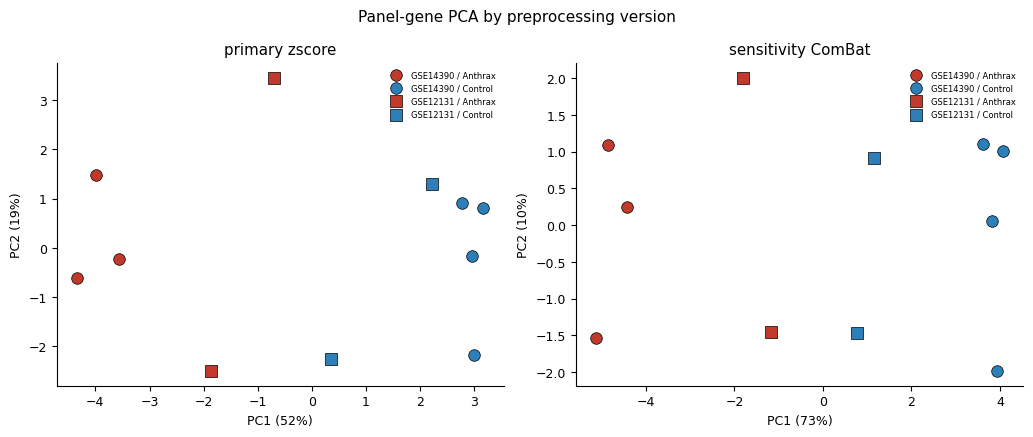

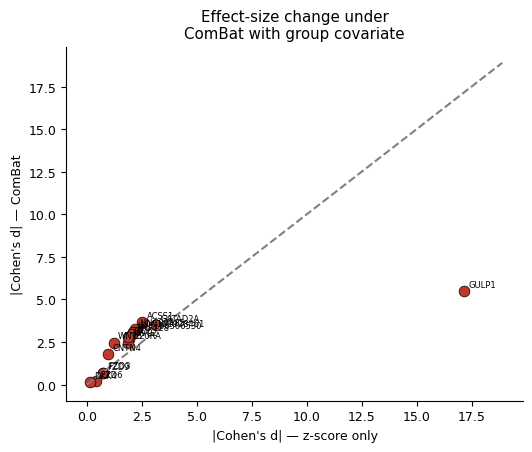

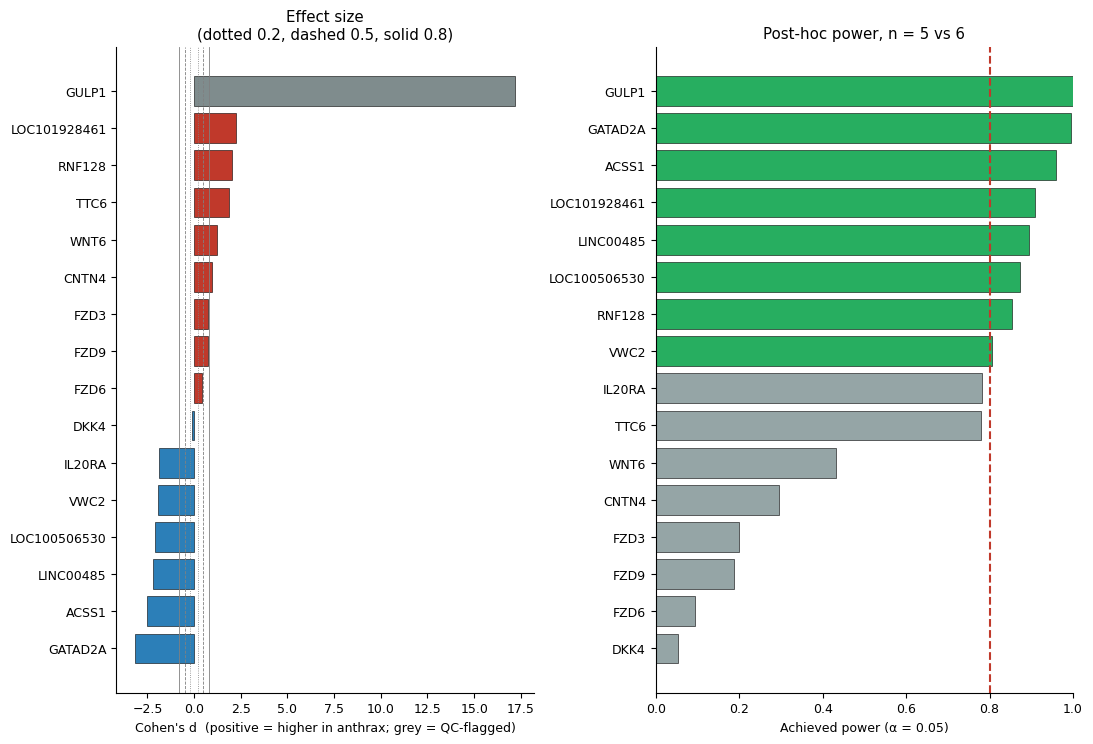

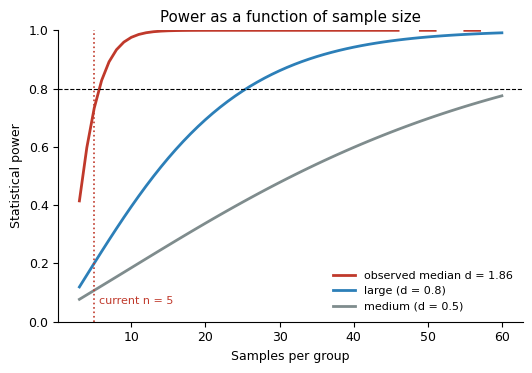

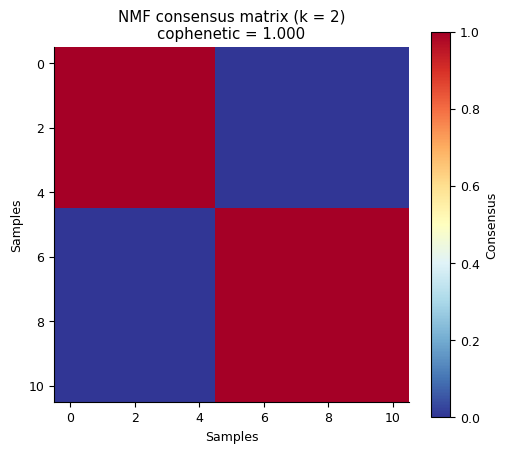


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v3/


In [ ]:
# ===== ANTHRAX STATISTICS v3 — POWER + FIRTH MODEL + NMF (selection-bias corrected) =====
from google.colab import drive; drive.mount('/content/drive')
import subprocess
subprocess.run("apt-get install -y r-base r-base-dev libcurl4-openssl-dev libssl-dev libxml2-dev",
               shell=True, capture_output=True)
subprocess.run("pip install -q rpy2 statsmodels scikit-learn", shell=True)

import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt
import rpy2.robjects as ro
from scipy import stats
from scipy.cluster.hierarchy import linkage, cophenet, fcluster
from scipy.spatial.distance import squareform
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import NMF

# ------------------------------- CONFIG -------------------------------
ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Statistics_Final_v3/"
FRESH_START = True

FIG, TAB, SUP = OUT+"Figures/", OUT+"Tables/", OUT+"Supplementary/"
SFIG = SUP + "Figures/"
if FRESH_START and os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB, SUP, SFIG): os.makedirs(d, exist_ok=True)
print(f"output root: {OUT}\n")

F_A, F_B = DATA+"GSE14390_gene_expression.csv", DATA+"GSE12131_gene_expression.csv"
F_MERGED = DATA + "merged_expr_scaled_common_genes.csv"

LABELS = {"GSM359332":0,"GSM359753":0,"GSM359754":0,"GSM359755":0,
          "GSM359758":1,"GSM359759":1,"GSM359760":1,
          "GSM305784":0,"GSM305785":0,"GSM305786":1,"GSM305787":1}
COHORT_OF = {**{g:"GSE14390" for g in list(LABELS)[:7]},
             **{g:"GSE12131" for g in list(LABELS)[7:]}}
PANEL = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
         "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
HUB   = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
ALL_G = list(dict.fromkeys(PANEL + HUB))

# genes excluded from the PREDICTION MODEL only (selection bias / extreme d).
# They remain in every power and descriptive table.
EXCLUDE_FROM_MODEL = ["GULP1"]
D_SUSPICIOUS, SD_DEGENERATE = 5.0, 0.05

ALPHA, POWER_TARGET, EPV_TARGET, SEED = 0.05, 0.80, 5, 42
np.random.seed(SEED)
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

# ------------------------------- LOAD -------------------------------
def read_gxs(path):
    df = pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors="coerce")
    df = df[df.notna().any(axis=1)]
    logged = float(np.nanmax(df.values)) > 50
    if logged: df = np.log2(df.clip(lower=0)+1)
    df.index = [re.sub(r"\.\d+$","",str(i)) for i in df.index]
    df = df[~df.index.astype(str).str.contains("///", regex=False)]
    return df.groupby(level=0).mean(), logged

print("="*80+"\nLOADING\n"+"="*80)
A, lgA = read_gxs(F_A); B, lgB = read_gxs(F_B)
print(f"  GSE14390: {A.shape[0]} genes x {A.shape[1]} samples (log2: {lgA})")
print(f"  GSE12131: {B.shape[0]} genes x {B.shape[1]} samples (log2: {lgB})")
shared = sorted(set(A.index) & set(B.index)); A, B = A.loc[shared], B.loc[shared]
Az = A.sub(A.mean(axis=1),axis=0).div(A.std(axis=1,ddof=0).replace(0,1),axis=0)
Bz = B.sub(B.mean(axis=1),axis=0).div(B.std(axis=1,ddof=0).replace(0,1),axis=0)
E_raw = pd.concat([Az, Bz], axis=1)
E_cb = None
if os.path.exists(F_MERGED):
    E_cb, _ = read_gxs(F_MERGED); print(f"  ComBat matrix: {E_cb.shape[1]} samples")
VERSIONS = {"primary_zscore": E_raw}
if E_cb is not None: VERSIONS["sensitivity_ComBat"] = E_cb

def prepare(E):
    s  = [c for c in E.columns if c in LABELS]
    y_ = np.array([LABELS[c] for c in s]); og = np.array([COHORT_OF[c] for c in s])
    g  = [x for x in ALL_G if x in E.index]
    Mx = E.loc[g, s].T
    return Mx.loc[:, Mx.notna().all()], y_, og, s

M, y, origin, samples = prepare(E_raw)
n1, n0 = int(y.sum()), int((1-y).sum())
print(f"  cohort: n={len(y)} ({n1} anthrax / {n0} control) | genes {len(M.columns)}/{len(ALL_G)}")

# PCA by preprocessing version
fig, axes = plt.subplots(1, len(VERSIONS), figsize=(5.2*len(VERSIONS), 4.4), squeeze=False)
for ax, (vname, Ev) in zip(axes[0], VERSIONS.items()):
    Mv, yv, ogv, _ = prepare(Ev)
    Xc = Mv.values - Mv.values.mean(axis=0)
    U, S, _ = np.linalg.svd(Xc, full_matrices=False)
    pcs = U[:, :2]*S[:2]; ev = 100*S**2/np.sum(S**2)
    for ds, mk in [("GSE14390","o"), ("GSE12131","s")]:
        for grp, col in [(1,"#c0392b"), (0,"#2c7fb8")]:
            m_ = (ogv==ds) & (yv==grp)
            if m_.any(): ax.scatter(pcs[m_,0], pcs[m_,1], marker=mk, c=col, s=70,
                                    edgecolor="black", lw=.5,
                                    label=f"{ds} / {'Anthrax' if grp else 'Control'}")
    ax.set_title(vname.replace("_"," ")); ax.legend(fontsize=6, frameon=False)
    ax.set_xlabel(f"PC1 ({ev[0]:.0f}%)"); ax.set_ylabel(f"PC2 ({ev[1]:.0f}%)")
fig.suptitle("Panel-gene PCA by preprocessing version", fontsize=11)
fig.tight_layout(); fig.savefig(SFIG+"FigS1_PCA_preprocessing.png", dpi=600, bbox_inches="tight")
fig.savefig(SFIG+"FigS1_PCA_preprocessing.pdf", bbox_inches="tight")

# =========================== 1. POST-HOC POWER ===========================
print("\n"+"="*80+"\n1. POST-HOC POWER ANALYSIS\n"+"="*80)
pa = TTestIndPower(); power_tables = {}
for vname, Ev in VERSIONS.items():
    Mv, yv, ogv, sv = prepare(Ev); rows = []
    for g in Mv.columns:
        a, c = Mv.loc[yv==1,g].dropna(), Mv.loc[yv==0,g].dropna()
        if len(a)<2 or len(c)<2: continue
        sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
        d  = (a.mean()-c.mean())/sp if sp>0 else 0.0
        tp = stats.ttest_ind(a,c,equal_var=False).pvalue
        wp = stats.mannwhitneyu(a,c,alternative="two-sided").pvalue
        try: ach = pa.solve_power(effect_size=abs(d), nobs1=len(a), ratio=len(c)/len(a),
                                  alpha=ALPHA, alternative="two-sided")
        except Exception: ach = np.nan
        need = np.nan
        if 0.01 < abs(d) < 10:
            try: need = pa.solve_power(effect_size=abs(d), power=POWER_TARGET, ratio=1.0,
                                       alpha=ALPHA, alternative="two-sided")
            except Exception: pass
        if abs(d) >= 10: need = 3.0            # solver fails; 3/group already suffices
        rows.append(dict(Version=vname, Gene=g,
            Set=("hub" if g in HUB and g not in PANEL else
                 "hub + common" if g in HUB else "common DEG"),
            N_anthrax=len(a), N_control=len(c), Mean_anthrax=a.mean(), Mean_control=c.mean(),
            SD_anthrax=a.std(ddof=1), SD_control=c.std(ddof=1), SD_pooled=sp,
            SD_ratio=max(a.std(ddof=1),c.std(ddof=1))/max(min(a.std(ddof=1),c.std(ddof=1)),1e-12),
            Ranges_overlap=(a.min()<=c.max()) and (c.min()<=a.max()),
            Cohens_d=d, Effect=("negligible" if abs(d)<.2 else "small" if abs(d)<.5 else
                                "medium" if abs(d)<.8 else "large"),
            t_test_p=tp, Wilcoxon_p=wp, Achieved_power=ach,
            Adequate=("Yes" if (ach or 0)>=POWER_TARGET else "No"),
            N_per_group_for_80pct=np.ceil(need) if np.isfinite(need) else np.nan))
    t = pd.DataFrame(rows)
    t["t_test_FDR"]   = multipletests(t.t_test_p, method="fdr_bh")[1]
    t["Wilcoxon_FDR"] = multipletests(t.Wilcoxon_p, method="fdr_bh")[1]
    t["QC_flag"] = np.where(t[["SD_anthrax","SD_control"]].min(axis=1) < SD_DEGENERATE,
                   "degenerate variance",
                   np.where(t.Cohens_d.abs() > D_SUSPICIOUS,
                            "extreme d — selection bias likely", "ok"))
    power_tables[vname] = t.sort_values("Achieved_power", ascending=False)
    tt = power_tables[vname]
    print(f"\n  --- {vname} (n={len(yv)}) ---")
    print(tt[["Gene","Set","Cohens_d","Effect","SD_ratio","Ranges_overlap",
              "t_test_FDR","Achieved_power","Adequate","N_per_group_for_80pct","QC_flag"]]
          .round(3).to_string(index=False))
    print(f"  power>={POWER_TARGET}: {(tt.Adequate=='Yes').sum()}/{len(tt)} | "
          f"median power {tt.Achieved_power.median():.3f} | "
          f"median n/group: {np.nanmedian(tt.N_per_group_for_80pct):.0f} | "
          f"flagged: {(tt.QC_flag!='ok').sum()}")

PW = power_tables["primary_zscore"]
pd.concat(power_tables.values()).round(4).to_csv(TAB+"Table1_posthoc_power.csv", index=False)
pd.DataFrame({"Sample":samples,"Dataset":origin,
              "Group":np.where(y==1,"Anthrax","Control")}).to_csv(
    SUP+"TableS1_sample_annotation.csv", index=False)

# within-cohort effect sizes (shows whether a large d is cohort-driven)
wc = []
for g in M.columns:
    row = {"Gene": g, "d_merged": PW.set_index("Gene").Cohens_d[g]}
    for ds in np.unique(origin):
        m_ = origin == ds
        aa, cc = M.loc[m_ & (y==1), g], M.loc[m_ & (y==0), g]
        if len(aa)>=2 and len(cc)>=2:
            s_ = np.sqrt(((len(aa)-1)*aa.var(ddof=1)+(len(cc)-1)*cc.var(ddof=1))
                         /(len(aa)+len(cc)-2))
            row[f"d_{ds}"] = (aa.mean()-cc.mean())/s_ if s_>0 else np.nan
        else: row[f"d_{ds}"] = np.nan
    row["Concordant_sign"] = (np.sign(row.get("d_GSE14390",np.nan)) ==
                              np.sign(row.get("d_GSE12131",np.nan)))
    wc.append(row)
WC = pd.DataFrame(wc).sort_values("d_merged", key=abs, ascending=False)
WC.round(3).to_csv(SUP+"TableS2_within_cohort_effect_sizes.csv", index=False)
print("\n  --- within-cohort effect sizes ---")
print(WC.round(2).to_string(index=False))
print(f"  sign-concordant across cohorts: {int(WC.Concordant_sign.sum())}/{len(WC)}")

cmp = None
if len(power_tables) > 1:
    a_, b_ = power_tables["primary_zscore"], power_tables["sensitivity_ComBat"]
    cmp = a_[["Gene","Cohens_d","Achieved_power","t_test_FDR"]].merge(
          b_[["Gene","Cohens_d","Achieved_power","t_test_FDR"]], on="Gene",
          suffixes=("_zscore","_ComBat"))
    cmp["d_inflation"] = cmp.Cohens_d_ComBat.abs() - cmp.Cohens_d_zscore.abs()
    cmp.sort_values("d_inflation", ascending=False).round(4).to_csv(
        SUP+"TableS3_preprocessing_comparison.csv", index=False)
    print(f"\n  ComBat d inflation: median {cmp.d_inflation.median():+.2f}, "
          f"max {cmp.d_inflation.max():+.2f}")
    figI, ax = plt.subplots(figsize=(5.4,4.6))
    ax.scatter(cmp.Cohens_d_zscore.abs(), cmp.Cohens_d_ComBat.abs(),
               c="#c0392b", s=60, edgecolor="black", lw=.5)
    lim = max(cmp.Cohens_d_ComBat.abs().max(), cmp.Cohens_d_zscore.abs().max())*1.1
    ax.plot([0,lim],[0,lim],"--",c="grey")
    for _, r in cmp.iterrows():
        ax.annotate(r.Gene, (abs(r.Cohens_d_zscore), abs(r.Cohens_d_ComBat)),
                    fontsize=6, xytext=(3,3), textcoords="offset points")
    ax.set_xlabel("|Cohen's d| — z-score only"); ax.set_ylabel("|Cohen's d| — ComBat")
    ax.set_title("Effect-size change under\nComBat with group covariate")
    figI.tight_layout(); figI.savefig(SFIG+"FigS2_effect_size_comparison.png", dpi=600)
    figI.savefig(SFIG+"FigS2_effect_size_comparison.pdf")

figP, ax = plt.subplots(1,2, figsize=(11,.32*len(PW)+2.4))
o = PW.sort_values("Cohens_d")
bar_c = [("#7f8c8d" if f!="ok" else ("#c0392b" if v>0 else "#2c7fb8"))
         for v,f in zip(o.Cohens_d, o.QC_flag)]
ax[0].barh(o.Gene, o.Cohens_d, color=bar_c, edgecolor="black", lw=.4)
for x_,s_ in [(.2,":"),(.5,"--"),(.8,"-")]:
    for sg in (1,-1): ax[0].axvline(sg*x_, ls=s_, c="grey", lw=.6)
ax[0].set_xlabel("Cohen's d  (positive = higher in anthrax; grey = QC-flagged)")
ax[0].set_title("Effect size\n(dotted 0.2, dashed 0.5, solid 0.8)")
o2 = PW.sort_values("Achieved_power")
ax[1].barh(o2.Gene, o2.Achieved_power,
           color=np.where(o2.Achieved_power>=POWER_TARGET,"#27ae60","#95a5a6"),
           edgecolor="black", lw=.4)
ax[1].axvline(POWER_TARGET, ls="--", c="#c0392b"); ax[1].set_xlim(0,1)
ax[1].set_xlabel(f"Achieved power (α = {ALPHA})")
ax[1].set_title(f"Post-hoc power, n = {n1} vs {n0}")
figP.tight_layout(); figP.savefig(FIG+"Fig1_posthoc_power.png", dpi=600, bbox_inches="tight")
figP.savefig(FIG+"Fig1_posthoc_power.pdf", bbox_inches="tight")

d_med = float(np.nanmedian(np.abs(PW[PW.QC_flag=="ok"].Cohens_d))); ns = np.arange(3,61)
figN, ax = plt.subplots(figsize=(5.4,3.8))
for d_,lab_,c_ in [(d_med,f"observed median d = {d_med:.2f}","#c0392b"),
                   (.8,"large (d = 0.8)","#2c7fb8"), (.5,"medium (d = 0.5)","#7f8c8d")]:
    ax.plot(ns, [pa.solve_power(effect_size=d_, nobs1=n, ratio=1., alpha=ALPHA) for n in ns],
            color=c_, lw=2, label=lab_)
ax.axhline(POWER_TARGET, ls="--", c="black", lw=.8)
ax.axvline(min(n1,n0), ls=":", c="#c0392b", lw=1.2)
ax.text(min(n1,n0)+.6,.06,f"current n = {min(n1,n0)}", fontsize=8, color="#c0392b")
ax.set_xlabel("Samples per group"); ax.set_ylabel("Statistical power"); ax.set_ylim(0,1)
ax.legend(fontsize=8, frameon=False); ax.set_title("Power as a function of sample size")
figN.tight_layout(); figN.savefig(FIG+"Fig2_power_vs_sample_size.png", dpi=600)
figN.savefig(FIG+"Fig2_power_vs_sample_size.pdf")

# =========================== 2. FIRTH MODEL ===========================
print("\n"+"="*80+"\n2. FIRTH MODEL, NOMOGRAM, CALIBRATION, DECISION CURVE\n"+"="*80)
auto_excl = list(PW[PW.QC_flag!="ok"].Gene)
excluded  = sorted(set(EXCLUDE_FROM_MODEL) | set(auto_excl))
cand = PW[~PW.Gene.isin(excluded)]
TOPK = max(1, min(len(cand), min(n1,n0)//EPV_TARGET))
sig  = list(cand.reindex(cand.Cohens_d.abs().sort_values(ascending=False).index).Gene[:TOPK])
print(f"  excluded from model: {', '.join(excluded) if excluded else 'none'}")
print(f"  events = {min(n1,n0)} | predictors = {TOPK} | EPV = {min(n1,n0)/TOPK:.1f}")
print(f"  signature: {', '.join(sig)}")
pd.DataFrame({"Gene":excluded,
              "Reason":[("pre-specified (selection bias)" if g in EXCLUDE_FROM_MODEL
                         else PW.set_index("Gene").QC_flag[g]) for g in excluded]}
             ).to_csv(SUP+"TableS4_model_exclusions.csv", index=False)
M[sig].assign(target=y, dataset=origin).to_csv(SUP+"TableS5_model_input.csv", index=False)

ro.globalenv['CSV']=SUP+"TableS5_model_input.csv"; ro.globalenv['FIG']=FIG
ro.globalenv['TAB']=TAB; ro.globalenv['SUP']=SUP; ro.globalenv['SIG']=ro.StrVector(sig)
ro.r('''
for (p in c("logistf","ggplot2","pROC"))
  if (!requireNamespace(p, quietly=TRUE))
    install.packages(p, repos="https://cloud.r-project.org", quiet=TRUE)
suppressPackageStartupMessages({library(logistf); library(ggplot2); library(pROC)})
d <- read.csv(CSV, check.names=TRUE); sig <- make.names(as.character(SIG))
d$target <- as.integer(d$target)
f <- as.formula(paste("target ~", paste(sprintf("`%s`", sig), collapse=" + ")))

fit <- logistf(f, data=d, firth=TRUE); k <- length(fit$coefficients)
res <- data.frame(Term=names(fit$coefficients), Coef=as.numeric(fit$coefficients),
  SE=sqrt(diag(fit$var))[1:k], CI_low=as.numeric(fit$ci.lower),
  CI_high=as.numeric(fit$ci.upper), OR=exp(as.numeric(fit$coefficients)),
  OR_low=exp(as.numeric(fit$ci.lower)), OR_high=exp(as.numeric(fit$ci.upper)),
  p=as.numeric(fit$prob))
cat("\\n--- Firth-penalised logistic regression ---\\n"); print(res, row.names=FALSE, digits=3)
write.csv(res, paste0(TAB,"Table2_firth_model.csv"), row.names=FALSE)

p_hat <- as.numeric(fit$predict); ev <- d$target; N <- length(ev)
a_app <- as.numeric(auc(roc(ev,p_hat,quiet=TRUE)))
cat(sprintf("\\nApparent AUC = %.3f  (fitted and scored on the same %d samples)\\n", a_app, N))

loo <- rep(NA_real_, N)
for (i in seq_len(N)) {
  m <- tryCatch(logistf(f, data=d[-i,], firth=TRUE), error=function(e) NULL)
  if (!is.null(m)) loo[i] <- 1/(1+exp(-sum(c(1, as.numeric(d[i,sig])) *
                                           as.numeric(m$coefficients))))
}
ok <- !is.na(loo)
if (sum(ok) > 3 && length(unique(ev[ok])) == 2) {
  rl <- roc(ev[ok], loo[ok], quiet=TRUE); a_loo <- as.numeric(auc(rl))
  ci <- as.numeric(ci.auc(rl))
  cat(sprintf("LOOCV AUC    = %.3f  (95%% CI %.3f - %.3f)   <- report this\\n",
              a_loo, ci[1], ci[3]))
  if (a_loo >= 0.999)
    cat("   NOTE: AUC = 1 makes the CI non-informative; describe as complete separation\\n")
  write.csv(data.frame(Sample=seq_len(N), Observed=ev, LOO_probability=loo),
            paste0(SUP,"TableS6_loo_predictions.csv"), row.names=FALSE)
  for (dv in list(function() png(paste0(FIG,"Fig3_ROC_loocv.png"), width=5.2, height=5.2,
                                 units="in", res=600),
                  function() pdf(paste0(FIG,"Fig3_ROC_loocv.pdf"), width=5.2, height=5.2))) {
    dv(); plot(rl, col="#c0392b", lwd=2,
      main=sprintf("Leave-one-out ROC (Firth model)\\nAUC = %.3f (95%% CI %.2f-%.2f)",
                   a_loo, ci[1], ci[3])); dev.off() }
}

co <- as.numeric(fit$coefficients); names(co) <- names(fit$coefficients)
pts <- do.call(rbind, lapply(sig, function(g){
  rg <- range(d[[g]]); sq <- seq(rg[1], rg[2], length.out=100)
  data.frame(Gene=g, Value=sq, LP=co[[g]]*sq) }))
pts$LP0 <- pts$LP - ave(pts$LP, pts$Gene, FUN=min)
mx <- max(pts$LP0); if (mx <= 0) mx <- 1
pts$Points <- 100*pts$LP0/mx
g1 <- ggplot(pts, aes(Value, Points)) + geom_line(linewidth=1.1, colour="#c0392b") +
  facet_wrap(~Gene, scales="free_x") +
  labs(x="Standardised expression", y="Points",
       title="Nomogram point allocation (Firth-penalised model)") + theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig4_nomogram.png"), g1, width=3.6*length(sig)+1.4, height=3.4,
       dpi=600, bg="white")
ggsave(paste0(FIG,"Fig4_nomogram.pdf"), g1, width=3.6*length(sig)+1.4, height=3.4)
tp <- data.frame(Total_points=seq(0,100*length(sig),by=5))
tp$Linear_predictor <- co[[1]] + (tp$Total_points/100)*mx
tp$Probability <- 1/(1+exp(-tp$Linear_predictor))
write.csv(tp, paste0(TAB,"Table3_nomogram_points.csv"), row.names=FALSE)

cal <- data.frame(Predicted=p_hat, Observed=ev)
cal$bin <- cut(cal$Predicted, breaks=seq(0,1,by=.25), include.lowest=TRUE)
cb <- aggregate(cbind(Predicted,Observed) ~ bin, data=cal, FUN=mean)
cb$n <- as.numeric(table(cal$bin)[as.character(cb$bin)])
write.csv(cb, paste0(TAB,"Table4_calibration_bins.csv"), row.names=FALSE)
g2 <- ggplot(cb, aes(Predicted, Observed)) +
  geom_abline(slope=1, intercept=0, linetype="dashed", colour="grey40") +
  geom_line(colour="#c0392b") + geom_point(aes(size=n), colour="#c0392b") +
  scale_size_continuous(range=c(2.5,6), name="n") +
  coord_cartesian(xlim=c(0,1), ylim=c(0,1)) +
  labs(x="Predicted probability", y="Observed frequency",
       title=sprintf("Calibration (quartile bins, n = %d)", N)) + theme_classic(base_size=11)
ggsave(paste0(FIG,"Fig5_calibration.png"), g2, width=4.8, height=4.4, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig5_calibration.pdf"), g2, width=4.8, height=4.4)

prev <- mean(ev); th <- seq(.01,.80,by=.01)
nb  <- sapply(th, function(t){ pos <- p_hat >= t
  (sum(pos & ev==1)/N) - (sum(pos & ev==0)/N)*(t/(1-t)) })
nba <- sapply(th, function(t) prev - (1-prev)*(t/(1-t)))
dca <- data.frame(Threshold=th, Net_benefit_model=nb,
                  Net_benefit_treat_all=nba, Net_benefit_treat_none=0)
write.csv(dca, paste0(TAB,"Table5_decision_curve.csv"), row.names=FALSE)
g3 <- ggplot(dca, aes(Threshold)) +
  geom_line(aes(y=Net_benefit_model, colour="Gene signature"), linewidth=1.1) +
  geom_line(aes(y=Net_benefit_treat_all, colour="Treat all"), linetype="dashed") +
  geom_line(aes(y=Net_benefit_treat_none, colour="Treat none"), linetype="dotted") +
  scale_colour_manual(values=c("Gene signature"="#c0392b","Treat all"="#2c7fb8",
                               "Treat none"="grey40"), name=NULL) +
  coord_cartesian(ylim=c(min(-.05,min(nb)), max(c(nb,prev))*1.1)) +
  labs(x="Threshold probability", y="Net benefit", title="Decision curve analysis") +
  theme_classic(base_size=11) + theme(legend.position="top")
ggsave(paste0(FIG,"Fig6_decision_curve.png"), g3, width=5.6, height=4.2, dpi=600, bg="white")
ggsave(paste0(FIG,"Fig6_decision_curve.pdf"), g3, width=5.6, height=4.2)
cat("\\nFirth model outputs written\\n")
''')

# =========================== 3. NMF ===========================
print("\n"+"="*80+"\n3. NMF MOLECULAR SUBTYPING\n"+"="*80)
V = M.values - M.values.min(); nmf_rows=[]; best=0.0
for k in range(2, min(5, len(y)//2 + 1)):
    C = np.zeros((len(y),len(y)))
    for r in range(50):
        H = NMF(n_components=k, init="nndsvda", random_state=SEED+r,
                max_iter=1000).fit_transform(V)
        lab = H.argmax(axis=1); C += (lab[:,None]==lab[None,:]).astype(float)
    C /= 50
    D = squareform(1-C, checks=False); Z = linkage(D,"average")
    coph = cophenet(Z,D)[0]; cl = fcluster(Z,k,"maxclust")
    sizes = np.bincount(cl)[1:]; k_eff = int((sizes>0).sum())
    agree = pd.crosstab(cl, np.where(y==1,"Anthrax","Control")).max(axis=1).sum()/len(y)
    best = max(best,coph)
    nmf_rows.append(dict(k_requested=k, k_effective=k_eff, Cophenetic=coph,
                         Dispersion=float((4*(C-.5)**2).mean()),
                         Agreement_with_group=agree,
                         Cluster_sizes=", ".join(map(str,sizes)),
                         Note=("collapsed to fewer clusters" if k_eff<k else "")))
    print(f"  k={k}: effective k={k_eff} | cophenetic {coph:.3f} | "
          f"group agreement {agree:.2f} | sizes {sizes}"
          + ("  <- collapsed" if k_eff<k else ""))
    if k == 2:
        pd.DataFrame({"Sample":samples,"Dataset":origin,
                      "Group":np.where(y==1,"Anthrax","Control"),"NMF_cluster":cl}
                     ).to_csv(SUP+"TableS7_NMF_subtypes_k2.csv", index=False)
        figC, ax = plt.subplots(figsize=(5.2,4.6))
        im = ax.imshow(C[np.argsort(cl)][:,np.argsort(cl)], cmap="RdYlBu_r", vmin=0, vmax=1)
        ax.set_title(f"NMF consensus matrix (k = 2)\ncophenetic = {coph:.3f}")
        ax.set_xlabel("Samples"); ax.set_ylabel("Samples")
        figC.colorbar(im, label="Consensus"); figC.tight_layout()
        figC.savefig(SFIG+"FigS3_NMF_consensus_k2.png", dpi=600)
        figC.savefig(SFIG+"FigS3_NMF_consensus_k2.pdf")
ND = pd.DataFrame(nmf_rows); ND.round(4).to_csv(SUP+"TableS8_NMF_rank_survey.csv", index=False)
collapsed = (ND.k_effective < ND.k_requested).any()
nmf_verdict = ("not interpretable — identical cophenetic across all k and/or collapsed clusters"
               if (ND.Cophenetic.nunique()==1 or collapsed) else
               "usable" if best>=0.90 else "unstable")
print(f"\n  verdict: {nmf_verdict}")

# =========================== VALIDITY REPORT ===========================
okg = PW[PW.QC_flag=="ok"]
rep = pd.DataFrame({"Item":[
    "Output folder","Primary matrix","Sensitivity matrix","Cohorts","Samples",
    "Anthrax / Control","Panel genes","QC-flagged genes","Genes power >= 0.80",
    "Median power (QC-passing)","Median |d| (QC-passing)","n per group for 80% power",
    "Genes FDR < 0.05","Sign-concordant across cohorts","Median d change under ComBat",
    "Model","Excluded from model","Predictors (EPV)","NMF verdict","Reporting guidance"],
  "Value":[OUT, "per-cohort z-score (no ComBat)",
    "ComBat with group covariate" if E_cb is not None else "not available",
    "GSE14390 + GSE12131", len(y), f"{n1} / {n0}", f"{len(M.columns)}/{len(ALL_G)}",
    int((PW.QC_flag!='ok').sum()), int((PW.Adequate=='Yes').sum()),
    round(okg.Achieved_power.median(),3), round(float(np.nanmedian(np.abs(okg.Cohens_d))),3),
    int(np.nanmedian(okg.N_per_group_for_80pct)), int((PW.t_test_FDR<0.05).sum()),
    f"{int(WC.Concordant_sign.sum())}/{len(WC)}",
    f"{cmp.d_inflation.median():+.2f}" if cmp is not None else "n/a",
    "Firth-penalised logistic (separation-safe)",
    ", ".join(excluded) if excluded else "none",
    f"{', '.join(sig)} (EPV {min(n1,n0)/max(TOPK,1):.1f})", nmf_verdict,
    "Report QC-passing effect sizes and required n; flagged genes descriptively only"]})
rep.to_csv(SUP+"TableS9_validity_report.csv", index=False)
print("\n"+"="*80+"\nVALIDITY REPORT\n"+"="*80)
print(rep.to_string(index=False))

print("\n--- OUTPUT INVENTORY ---")
for folder, lbl in [(FIG,"Figures"), (TAB,"Tables"), (SUP,"Supplementary"),
                    (SFIG,"Supplementary figures")]:
    fs = sorted(f for f in os.listdir(folder) if os.path.isfile(os.path.join(folder,f)))
    print(f"\n{lbl}:")
    for f in fs: print(f"   {f}")
plt.show(); print("\nSaved ->", OUT)


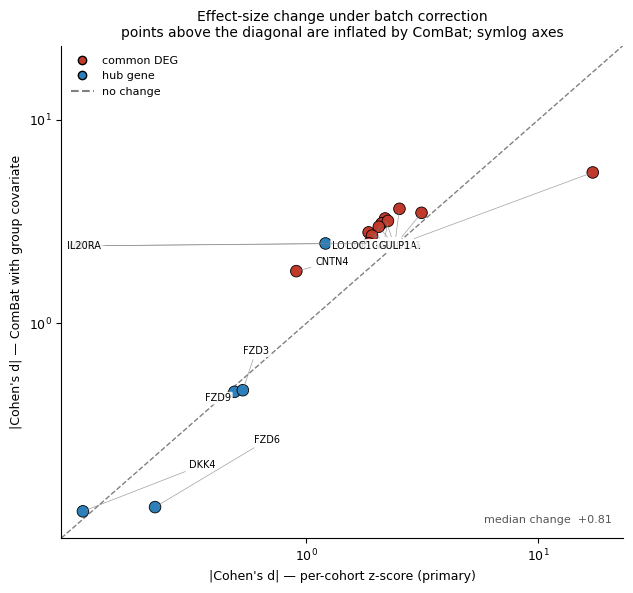

replaced -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v3/Supplementary/Figures/FigS2_effect_size_comparison.png/.pdf


In [ ]:
# ===== REPLACE FigS2 — readable label placement, symlog axes =====
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

OUT  = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Statistics_Final_v3/"
SUP  = OUT + "Supplementary/"
SFIG = SUP + "Figures/"
HUB  = {"WNT6","FZD9","DKK4","FZD6","FZD3"}
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

cmp = pd.read_csv(SUP + "TableS3_preprocessing_comparison.csv")
x = cmp.Cohens_d_zscore.abs().values
z = cmp.Cohens_d_ComBat.abs().values
lab = cmp.Gene.values

def repel(ax, xs, ys, labels, iters=600, k=160):
    """force-directed label placement in axis-fraction space, with leader lines"""
    xr, yr = ax.get_xlim(), ax.get_ylim()
    fx_ = lambda v: (ax.transLimits.transform((v, yr[0]))[0])
    fy_ = lambda v: (ax.transLimits.transform((xr[0], v))[1])
    px = np.array([fx_(v) for v in xs]); py = np.array([fy_(v) for v in ys])
    lx, ly = px.copy()+0.03, py.copy()+0.03
    for _ in range(iters):
        for i in range(len(lx)):
            ax_, ay_ = 0.0, 0.0
            for j in range(len(lx)):
                if i == j: continue
                dx, dy = lx[i]-lx[j], ly[i]-ly[j]
                d2 = dx*dx + dy*dy + 1e-7
                if d2 < 0.010: ax_ += dx/d2/k; ay_ += dy/d2/k
            dx, dy = lx[i]-px[i], ly[i]-py[i]
            d2 = dx*dx + dy*dy + 1e-7
            if d2 < 0.0006: ax_ += dx/d2/k; ay_ += dy/d2/k
            ax_ -= dx*0.006; ay_ -= dy*0.006
            lx[i] = np.clip(lx[i]+ax_, 0.03, 0.97)
            ly[i] = np.clip(ly[i]+ay_, 0.03, 0.97)
    inv = ax.transLimits.inverted()
    for i, t in enumerate(labels):
        tx, ty = inv.transform((lx[i], ly[i]))
        ax.annotate(t, xy=(xs[i], ys[i]), xytext=(tx, ty), fontsize=7,
                    ha="center", va="center",
                    arrowprops=dict(arrowstyle="-", lw=0.5, color="grey", alpha=0.75),
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

fig, ax = plt.subplots(figsize=(6.4, 6.0))
lim = max(x.max(), z.max()) * 1.35
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set_xlim(0.05, lim); ax.set_ylim(0.05, lim)
ax.plot([0.05, lim], [0.05, lim], "--", c="grey", lw=1, zorder=1,
        label="no change")
col = ["#2c7fb8" if g in HUB else "#c0392b" for g in lab]
ax.scatter(x, z, c=col, s=70, edgecolor="black", lw=0.6, zorder=3)
repel(ax, x, z, lab)
ax.set_xlabel("|Cohen's d| — per-cohort z-score (primary)")
ax.set_ylabel("|Cohen's d| — ComBat with group covariate")
ax.set_title("Effect-size change under batch correction\n"
             "points above the diagonal are inflated by ComBat; symlog axes",
             fontsize=10)
ax.legend(handles=[Line2D([],[],marker="o",ls="",mfc="#c0392b",mec="black",
                          label="common DEG"),
                   Line2D([],[],marker="o",ls="",mfc="#2c7fb8",mec="black",
                          label="hub gene"),
                   Line2D([],[],ls="--",c="grey",label="no change")],
          loc="upper left", fontsize=8, frameon=False)
med = np.median(z - x)
ax.text(0.98, 0.03, f"median change  {med:+.2f}", transform=ax.transAxes,
        ha="right", fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(SFIG+"FigS2_effect_size_comparison.png", dpi=600, bbox_inches="tight")
fig.savefig(SFIG+"FigS2_effect_size_comparison.pdf", bbox_inches="tight")
plt.show()
print("replaced ->", SFIG+"FigS2_effect_size_comparison.png/.pdf")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1. SCALE DIAGNOSTIC (raw, before any transform)
  Cohort  genes  samples    min   q25  median     q75       max       sd  pct_negative     IQR                likely_scale
GSE14390  21591        7 -1.899 0.297   1.058   1.671     4.388    1.281        20.239   1.374 log-ratio / already centred
GSE12131  21591        4  0.039 7.704  32.879 268.832 22773.100 1252.246         0.000 261.128               raw intensity

  per-gene SD ratio (GSE14390 / GSE12131): 0.04
  -> a ratio far from 1 is what inflates within-cohort Cohen's d

2. WITHIN-COHORT EFFECT SIZES UNDER EACH HARMONISATION

  --- a_genewise_zscore ---
        Gene  d_merged  d_GSE14390  d_GSE12131  Concordant  d_ratio
       GULP1     17.18       18.77       25.84        True     0.73
     GATAD2A     -3.14      -15.38       -1.21        True    12.74
       ACSS1     -2.52      -15.07       -0.82     

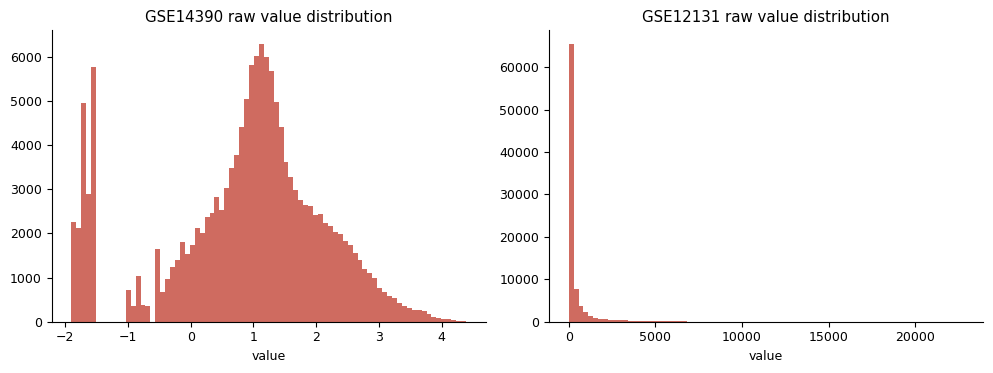

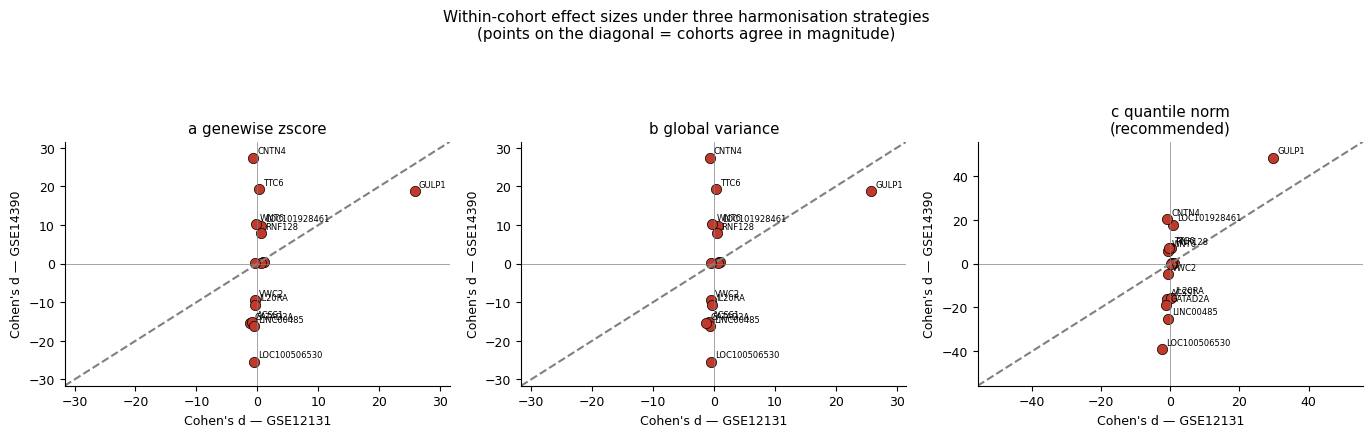


Saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Scale_Diagnostic/


In [ ]:
# ===== SCALE DIAGNOSTIC + HARMONISATION — within-cohort effect-size repair =====
from google.colab import drive; drive.mount('/content/drive')
import os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/"
DATA = ROOT + "Datasets/"
OUT  = ROOT + "Final/Scale_Diagnostic/"
FIG, TAB = OUT+"Figures/", OUT+"Tables/"
if os.path.isdir(OUT): shutil.rmtree(OUT)
for d in (OUT, FIG, TAB): os.makedirs(d, exist_ok=True)

F_A, F_B = DATA+"GSE14390_gene_expression.csv", DATA+"GSE12131_gene_expression.csv"
LABELS = {"GSM359332":0,"GSM359753":0,"GSM359754":0,"GSM359755":0,
          "GSM359758":1,"GSM359759":1,"GSM359760":1,
          "GSM305784":0,"GSM305785":0,"GSM305786":1,"GSM305787":1}
PANEL = ["GULP1","GATAD2A","ACSS1","LOC100506530","CNTN4","LINC00485",
         "WNT6","LOC101928461","IL20RA","VWC2","RNF128","TTC6"]
HUB   = ["WNT6","FZD9","DKK4","FZD6","FZD3"]
ALL_G = list(dict.fromkeys(PANEL+HUB))
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

def raw_load(path):
    df = pd.read_csv(path, index_col=0).apply(pd.to_numeric, errors="coerce")
    df = df[df.notna().any(axis=1)]
    df.index = [re.sub(r"\.\d+$","",str(i)) for i in df.index]
    df = df[~df.index.astype(str).str.contains("///", regex=False)]
    return df.groupby(level=0).mean()

A0, B0 = raw_load(F_A), raw_load(F_B)
shared = sorted(set(A0.index) & set(B0.index)); A0, B0 = A0.loc[shared], B0.loc[shared]

# ------------------------------- 1. DIAGNOSE -------------------------------
print("="*80+"\n1. SCALE DIAGNOSTIC (raw, before any transform)\n"+"="*80)
diag = []
for nm, X in [("GSE14390", A0), ("GSE12131", B0)]:
    v = X.values[np.isfinite(X.values)]
    neg = float((v < 0).mean()*100)
    diag.append(dict(Cohort=nm, genes=X.shape[0], samples=X.shape[1],
        min=v.min(), q25=np.percentile(v,25), median=np.median(v),
        q75=np.percentile(v,75), max=v.max(), sd=v.std(),
        pct_negative=neg, IQR=np.percentile(v,75)-np.percentile(v,25),
        likely_scale=("log-ratio / already centred" if neg > 5 else
                      "log2 intensity" if v.max() < 25 else "raw intensity")))
D = pd.DataFrame(diag); print(D.round(3).to_string(index=False))
D.round(4).to_csv(TAB+"Table_scale_diagnostic.csv", index=False)
print(f"\n  per-gene SD ratio (GSE14390 / GSE12131): "
      f"{A0.std(axis=1).median()/B0.std(axis=1).median():.2f}")
print("  -> a ratio far from 1 is what inflates within-cohort Cohen's d")

fig, ax = plt.subplots(1,2, figsize=(10,3.8))
for a_, (nm, X) in zip(ax, [("GSE14390",A0), ("GSE12131",B0)]):
    a_.hist(X.values[np.isfinite(X.values)].ravel(), bins=80, color="#c0392b", alpha=.75)
    a_.set_title(f"{nm} raw value distribution"); a_.set_xlabel("value")
fig.tight_layout(); fig.savefig(FIG+"Fig_raw_distributions.png", dpi=600)

# ------------------------------- 2. THREE HARMONISATIONS -------------------------------
def log_if_raw(X):
    return np.log2(X.clip(lower=0)+1) if float(np.nanmax(X.values)) > 50 else X.copy()

def quantile_normalise(X, ref_quantiles):
    """map each sample's ranks onto a common reference distribution"""
    out = X.copy()
    for c in X.columns:
        order = X[c].rank(method="first").astype(int) - 1
        out[c] = ref_quantiles[order.values]
    return out

A1, B1 = log_if_raw(A0), log_if_raw(B0)

# (a) gene-wise z-score within each cohort  [what v3 used]
Az = A1.sub(A1.mean(axis=1),axis=0).div(A1.std(axis=1,ddof=0).replace(0,1),axis=0)
Bz = B1.sub(B1.mean(axis=1),axis=0).div(B1.std(axis=1,ddof=0).replace(0,1),axis=0)

# (b) per-cohort global variance scaling: preserves relative gene spread,
#     equalises overall dynamic range between cohorts
Ag = (A1 - A1.values.mean()) / A1.values.std()
Bg = (B1 - B1.values.mean()) / B1.values.std()

# (c) quantile normalisation to a pooled reference distribution
ref = np.sort(np.concatenate([A1.values.ravel(), B1.values.ravel()]))
ref = np.interp(np.linspace(0, len(ref)-1, A1.shape[0]), np.arange(len(ref)), ref)
Aq, Bq = quantile_normalise(A1, ref), quantile_normalise(B1, ref)

METHODS = {"a_genewise_zscore": (Az, Bz),
           "b_global_variance": (Ag, Bg),
           "c_quantile_norm":   (Aq, Bq)}

def cohens_d(a, c):
    if len(a) < 2 or len(c) < 2: return np.nan
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(c)-1)*c.var(ddof=1))/(len(a)+len(c)-2))
    return (a.mean()-c.mean())/sp if sp > 0 else np.nan

print("\n"+"="*80+"\n2. WITHIN-COHORT EFFECT SIZES UNDER EACH HARMONISATION\n"+"="*80)
results = {}
for mname, (Ax, Bx) in METHODS.items():
    E = pd.concat([Ax, Bx], axis=1)
    s = [c for c in E.columns if c in LABELS]
    y = np.array([LABELS[c] for c in s])
    og = np.array(["GSE14390" if c in A0.columns else "GSE12131" for c in s])
    g = [x for x in ALL_G if x in E.index]
    M = E.loc[g, s].T
    rows = []
    for gene in M.columns:
        r = {"Gene": gene,
             "d_merged": cohens_d(M.loc[y==1,gene], M.loc[y==0,gene])}
        for ds in ["GSE14390","GSE12131"]:
            m_ = og == ds
            r[f"d_{ds}"] = cohens_d(M.loc[m_&(y==1),gene], M.loc[m_&(y==0),gene])
        r["Concordant"] = np.sign(r["d_GSE14390"]) == np.sign(r["d_GSE12131"])
        r["d_ratio"] = (abs(r["d_GSE14390"])/max(abs(r["d_GSE12131"]), 1e-9))
        rows.append(r)
    T = pd.DataFrame(rows).sort_values("d_merged", key=abs, ascending=False)
    results[mname] = T
    fin = T[np.isfinite(T.d_ratio)]
    print(f"\n  --- {mname} ---")
    print(T.round(2).to_string(index=False))
    print(f"  concordant: {int(T.Concordant.sum())}/{len(T)} | "
          f"median |d| GSE14390 {T.d_GSE14390.abs().median():.2f} vs "
          f"GSE12131 {T.d_GSE12131.abs().median():.2f} | "
          f"median d-ratio {fin.d_ratio.median():.1f}  "
          f"(1 = balanced; >5 = one cohort dominates)")
    T.round(4).to_csv(TAB+f"Table_within_cohort_{mname}.csv", index=False)

# ------------------------------- 3. PICK THE BALANCED ONE -------------------------------
summary = pd.DataFrame([{
    "Method": m,
    "Concordant": f"{int(T.Concordant.sum())}/{len(T)}",
    "median_abs_d_GSE14390": T.d_GSE14390.abs().median(),
    "median_abs_d_GSE12131": T.d_GSE12131.abs().median(),
    "median_d_ratio": T[np.isfinite(T.d_ratio)].d_ratio.median(),
    "max_abs_d": T[["d_GSE14390","d_GSE12131"]].abs().max().max(),
    "implausible_d_gt_10": int((T[["d_GSE14390","d_GSE12131"]].abs() > 10).sum().sum()),
} for m, T in results.items()])
summary["balance_score"] = abs(np.log10(summary.median_d_ratio.clip(lower=1e-9)))
summary = summary.sort_values(["implausible_d_gt_10","balance_score"])
print("\n"+"="*80+"\n3. METHOD COMPARISON\n"+"="*80)
print(summary.round(3).to_string(index=False))
summary.round(4).to_csv(TAB+"Table_method_comparison.csv", index=False)
best = summary.Method.iloc[0]
print(f"\n  recommended: {best}  (fewest implausible |d| > 10, most balanced cohorts)")

fig, axes = plt.subplots(1, len(results), figsize=(4.6*len(results), 4.4), squeeze=False)
for ax, (m, T) in zip(axes[0], results.items()):
    ax.scatter(T.d_GSE12131, T.d_GSE14390, c="#c0392b", s=55, edgecolor="black", lw=.5)
    lim = max(T[["d_GSE12131","d_GSE14390"]].abs().max().max()*1.15, 3)
    ax.plot([-lim,lim],[-lim,lim],"--",c="grey"); ax.axhline(0,c="grey",lw=.5)
    ax.axvline(0,c="grey",lw=.5); ax.set_xlim(-lim,lim); ax.set_ylim(-lim,lim)
    for _, r in T.iterrows():
        if abs(r.d_GSE14390) > 2 or abs(r.d_GSE12131) > 2:
            ax.annotate(r.Gene, (r.d_GSE12131, r.d_GSE14390), fontsize=6,
                        xytext=(3,3), textcoords="offset points")
    ax.set_xlabel("Cohen's d — GSE12131"); ax.set_ylabel("Cohen's d — GSE14390")
    ax.set_title(m.replace("_"," ") + ("\n(recommended)" if m == best else ""))
fig.suptitle("Within-cohort effect sizes under three harmonisation strategies\n"
             "(points on the diagonal = cohorts agree in magnitude)", fontsize=11)
fig.tight_layout(rect=[0,0,1,.90])
fig.savefig(FIG+"Fig_harmonisation_comparison.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig_harmonisation_comparison.pdf", bbox_inches="tight")

# ------------------------------- 4. WRITE THE CHOSEN MATRIX -------------------------------
Ax, Bx = METHODS[best]
E_best = pd.concat([Ax, Bx], axis=1)
path = DATA + f"harmonised_{best}.csv"
E_best.to_csv(path)
print(f"\n  harmonised matrix written: {path}")
print(f"  -> in the v3 statistics cell, replace the z-score block with:")
print(f"       E_raw, _ = read_gxs('{path}')")
plt.show(); print("\nSaved ->", OUT)

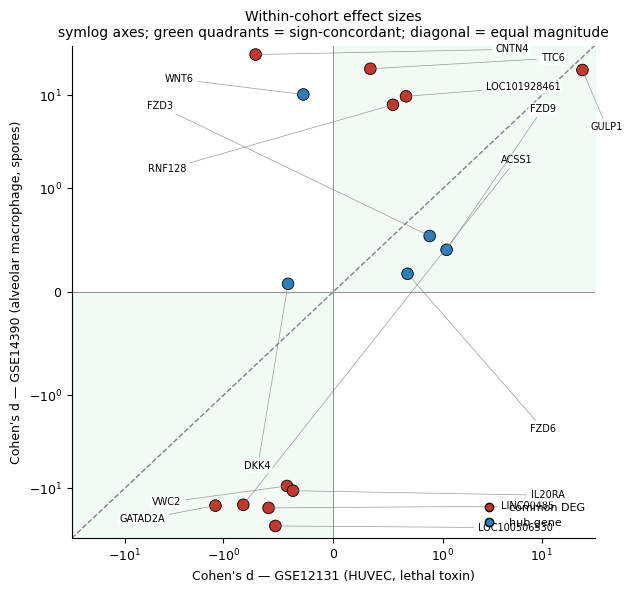

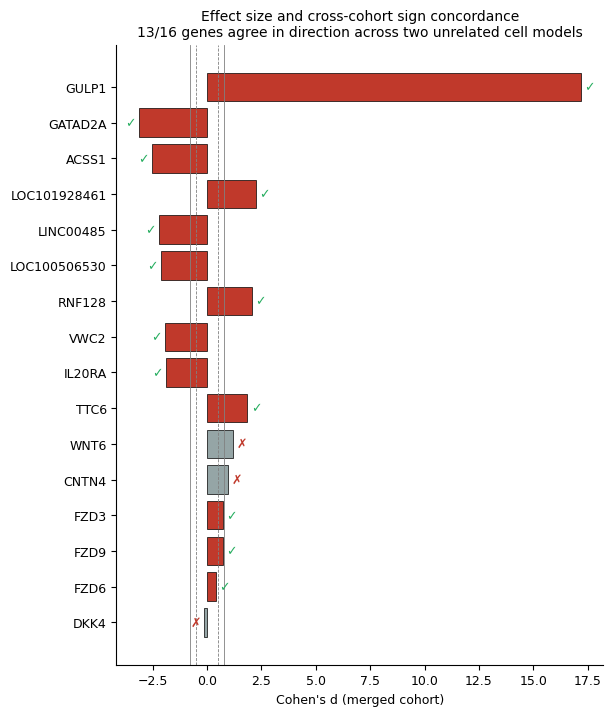

saved -> /content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Scale_Diagnostic/Figures/


In [ ]:
# ===== CLEAN HARMONISATION FIGURE (readable labels, symlog axes) =====
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

OUT = "/content/drive/MyDrive/research/Anthrax/Anthraxpaper/Final/Scale_Diagnostic/"
FIG, TAB = OUT+"Figures/", OUT+"Tables/"
plt.rcParams.update({"font.size":9,"axes.spines.top":False,"axes.spines.right":False})

T = pd.read_csv(TAB+"Table_within_cohort_a_genewise_zscore.csv")
HUB = {"WNT6","FZD9","DKK4","FZD6","FZD3"}

def repel(ax, xs, ys, labels, k=180, iters=400):
    """simple force-directed label placement in axis-fraction space"""
    xr = ax.get_xlim(); yr = ax.get_ylim()
    sx, sy = xr[1]-xr[0], yr[1]-yr[0]
    px = np.array([(x-xr[0])/sx for x in xs]); py = np.array([(y-yr[0])/sy for y in ys])
    lx, ly = px + .02, py + .02
    for _ in range(iters):
        for i in range(len(lx)):
            fx = fy = 0.0
            for j in range(len(lx)):
                if i == j: continue
                dx, dy = lx[i]-lx[j], ly[i]-ly[j]
                d2 = dx*dx + dy*dy + 1e-6
                if d2 < .006: fx += dx/d2/k; fy += dy/d2/k
            dx, dy = lx[i]-px[i], ly[i]-py[i]
            d2 = dx*dx + dy*dy + 1e-6
            if d2 < .0004: fx += dx/d2/k; fy += dy/d2/k
            fx -= dx*.004; fy -= dy*.004          # tether to the point
            lx[i] = np.clip(lx[i]+fx, .02, .98); ly[i] = np.clip(ly[i]+fy, .02, .98)
    for i, lab in enumerate(labels):
        ax.annotate(lab, xy=(xs[i], ys[i]),
                    xytext=(xr[0]+lx[i]*sx, yr[0]+ly[i]*sy), fontsize=7,
                    arrowprops=dict(arrowstyle="-", lw=.5, color="grey", alpha=.8),
                    bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.8))

fig, ax = plt.subplots(figsize=(6.4, 6.0))
col = ["#2c7fb8" if g in HUB else "#c0392b" for g in T.Gene]
ax.scatter(T.d_GSE12131, T.d_GSE14390, c=col, s=70, edgecolor="black", lw=.6, zorder=3)
lim = max(T[["d_GSE12131","d_GSE14390"]].abs().max().max()*1.25, 5)
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.plot([-lim,lim], [-lim,lim], "--", c="grey", lw=1, zorder=1)
ax.axhline(0, c="grey", lw=.6, zorder=1); ax.axvline(0, c="grey", lw=.6, zorder=1)
ax.fill_between([-lim,0],[0,0],[-lim,-lim],color="#27ae60",alpha=.05,zorder=0)
ax.fill_between([0,lim],[0,0],[lim,lim],color="#27ae60",alpha=.05,zorder=0)
repel(ax, T.d_GSE12131.values, T.d_GSE14390.values, T.Gene.values)
ax.set_xlabel("Cohen's d — GSE12131 (HUVEC, lethal toxin)")
ax.set_ylabel("Cohen's d — GSE14390 (alveolar macrophage, spores)")
ax.set_title("Within-cohort effect sizes\n"
             "symlog axes; green quadrants = sign-concordant; diagonal = equal magnitude",
             fontsize=10)
ax.legend(handles=[Line2D([],[],marker="o",ls="",mfc="#c0392b",mec="black",label="common DEG"),
                   Line2D([],[],marker="o",ls="",mfc="#2c7fb8",mec="black",label="hub gene")],
          loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG+"Fig_within_cohort_clean.png", dpi=600, bbox_inches="tight")
fig.savefig(FIG+"Fig_within_cohort_clean.pdf", bbox_inches="tight")

# --- the figure you should actually publish: sign concordance only ---
S = T.sort_values("d_merged", key=abs, ascending=False)
fig2, ax = plt.subplots(figsize=(6.2, .34*len(S)+1.8))
yp = np.arange(len(S))[::-1]
ax.barh(yp, S.d_merged, color=np.where(S.Concordant,"#c0392b","#95a5a6"),
        edgecolor="black", lw=.5)
for i, (_, r) in zip(yp, S.iterrows()):
    mark = "✓" if r.Concordant else "✗"
    ax.text(r.d_merged + (.15 if r.d_merged>0 else -.15), i, mark,
            va="center", ha="left" if r.d_merged>0 else "right", fontsize=9,
            color="#27ae60" if r.Concordant else "#c0392b")
for x_, s_ in [(.5,"--"),(.8,"-")]:
    for sg in (1,-1): ax.axvline(sg*x_, ls=s_, c="grey", lw=.6)
ax.set_yticks(yp); ax.set_yticklabels(S.Gene)
ax.set_xlabel("Cohen's d (merged cohort)")
ax.set_title(f"Effect size and cross-cohort sign concordance\n"
             f"{int(S.Concordant.sum())}/{len(S)} genes agree in direction "
             f"across two unrelated cell models", fontsize=10)
fig2.tight_layout()
fig2.savefig(FIG+"Fig_sign_concordance.png", dpi=600, bbox_inches="tight")
fig2.savefig(FIG+"Fig_sign_concordance.pdf", bbox_inches="tight")
plt.show()
print("saved ->", FIG)